# Mapping Nigeria's Digital Divide
### DSN AI Bootcamp 2026, Geospatial Track

**Question.** Which communities have poor internet connectivity relative to their population, settlements and needs, and where should improvements be prioritised?

**Approach**
1. Start from where people live (GRID3 settlements, WorldPop population), not from where speed tests happened.
2. Match each settlement to Ookla speed tiles. A settlement with no tile is *unmeasured*.
3. Add cell towers, wealth, health facilities and schools.
4. Score every LGA with a Priority Index, then roll up to states and geopolitical zones.
5. Rank zones, then states, then the LGAs inside them, and shortlist towers to upgrade first.

**Outputs** are written to `outputs/` (maps, tables) and `outputs/web/` (files for the web app).

## How to run

* Run from the `notebooks/` folder with the project environment active.
* The large files (settlements, population raster, schools) sit under `Data/` and are not committed to git.
* The settlement step takes several minutes and is cached in `cache/`. Set `QUICK_RUN = True` below to test on the first 500,000 blocks.

## 1. Setup

In [4]:
import heapq
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import pyogrio
import rasterio
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import folium
from pyproj import Transformer
from rasterstats import zonal_stats
from scipy import stats
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [5]:
# Folders (notebook lives in notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, OUT, CACHE = ROOT / "Data", ROOT / "outputs", ROOT / "cache"
WEB = OUT / "web"
for folder in (OUT, CACHE, WEB):
    folder.mkdir(parents=True, exist_ok=True)

def find_file(patterns, exclude=()):
    """First file under Data/ matching any pattern."""
    for pattern in patterns:
        for path in sorted(DATA.rglob(pattern)):
            if not any(word in path.name.lower() for word in exclude):
                return path
    raise FileNotFoundError(f"No file under {DATA} matches {patterns}")

# Input files
OOKLA_GPKG = DATA / "Nigeria Ookla.gpkg"
LGA_SHP = DATA / "NGA_LGA_Boundaries" / "grid3_nga_boundary_vacclgas.shp"
STATE_SHP = DATA / "NGA_State_Boundaries_V2" / "grid3_nga_boundary_vaccstates.shp"
HEALTH_SHP = DATA / "GRID3_NGA_health_facilities" / "GRID3_NGA_health_facilities_v2_0.shp"
TOWERS_CSV = DATA / "cell_towers.csv"
WEALTH_CSV = DATA / "nga_relative_wealth_index.csv"
SCHOOLS_SHP = find_file(["grid3_nga_poi_school.shp", "*school*.shp"])
POP_RASTER = find_file(["nga_pop_2020_CN_100m.tif", "*pop*.tif"])
SETTLEMENT_GPKG = find_file(["*settlement*.gdb", "*settlement*", "*.gpkg"], exclude=("ookla",))

for name, path in [("Settlements", SETTLEMENT_GPKG), ("Population", POP_RASTER), ("Schools", SCHOOLS_SHP)]:
    print(f"{name:<12}{path.relative_to(ROOT)}")

Settlements Data\GRID3_NGA_settlement_extents.gdb
Population  Data\nga_pop_2020_CN_100m.tif
Schools     Data\Schools_in_Nigeria\grid3_nga_poi_school.shp


In [6]:
# Settings used in the analysis
CRS_GEO = "EPSG:4326"       # storage and web maps
CRS_DIST = "EPSG:32632"     # UTM 32N, used only to measure distances in metres
BROADBAND_MBPS = 10.0       # measured speed below this counts as slow
HIGH_SPEED_MBPS = 25.0      # reference for good service
MIN_TESTS = 1               # speed tests needed for a tile to count as measured
FAR_FROM_TOWER_KM = 5.0     # farther than this from any tower is "remote"
RWI_MAX_DIST_KM = 5.0       # furthest distance to borrow a wealth value from
SITE_RADIUS_KM = 3.0        # assumed reach of an upgraded tower
N_SITES = 100               # length of the tower shortlist
CELL_KM = 1.0               # grid cell for the siting step
PRIORITY_QUANTILE = 0.80    # top fifth of LGAs form the priority set
CHUNK = 250_000             # settlement blocks processed at a time
QUICK_RUN = False           # True: test on the first 500,000 blocks only
RANDOM_SEED = 42

# Priority Index weights (sum to 1), explained in section 9
WEIGHTS = {"service_gap": 0.30, "exposure": 0.20, "infra_gap": 0.15, "need": 0.20, "institution_gap": 0.15}

ZONES = {"NCZ": "North Central", "NEZ": "North East", "NWZ": "North West",
         "SEZ": "South East", "SSZ": "South South", "SWZ": "South West"}

# Colours
C_DARK, C_ACCENT, C_MID, C_OK, C_COOL = "#1f2a44", "#c8442f", "#e8a33d", "#3b8f6b", "#3f6fb5"
QUINTILES = ["Q1 lowest", "Q2", "Q3", "Q4", "Q5 highest"]
QUINTILE_COLORS = ["#fff1d6", "#fcd08a", "#f29b4b", "#d9582b", "#8f1d14"]
SPEED_BINS = [0, 5, 10, 25, 50, np.inf]
SPEED_LABELS = ["< 5", "5 to 10", "10 to 25", "25 to 50", "50 +"]
SPEED_COLORS = ["#440154", "#3b528b", "#21908d", "#5dc863", "#fde725"]

## 2. Load the data

### 2.1 Ookla speed tiles

The GeoPackage holds two layers with the same 9,234 tiles, and one has no coordinate system. The code uses the WGS 84 layer.

In [7]:
ookla_layers = pyogrio.list_layers(OOKLA_GPKG)[:, 0].tolist()
layer_info = {name: pyogrio.read_info(OOKLA_GPKG, layer=name) for name in ookla_layers}
for name, info in layer_info.items():
    print(f"layer {name!r}: {info['features']:,} features, CRS = {info['crs']}")

def is_wgs84(crs):
    return any(token in str(crs or "") for token in ("4326", "WGS 84", "WGS_1984", "WGS84"))

# Use the layer with a valid coordinate system
OOKLA_LAYER = next((n for n, i in layer_info.items() if is_wgs84(i["crs"])), ookla_layers[0])
ookla = gpd.read_file(OOKLA_GPKG, layer=OOKLA_LAYER)
if ookla.crs is None or not ookla.crs.is_geographic:
    ookla = ookla.set_crs(CRS_GEO, allow_override=True)
ookla = ookla.to_crs(CRS_GEO)
assert ookla["tile_x"].between(2, 15).all() and ookla["tile_y"].between(4, 14).all(), "Tiles are outside Nigeria"

ookla["dl_mbps"] = ookla["avg_d_kbps"] / 1000
ookla["ul_mbps"] = ookla["avg_u_kbps"] / 1000
print(f"\nUsing layer {OOKLA_LAYER!r}: {len(ookla):,} tiles")
ookla[["dl_mbps", "ul_mbps", "avg_lat_ms", "tests", "devices"]].describe().T

layer 'Nigeria Ookla': 9,234 features, CRS = None
layer 'nigeria_ookla': 9,234 features, CRS = EPSG:4326

Using layer 'nigeria_ookla': 9,234 tiles


,count,mean,std,min,25%,50%,75%,max
dl_mbps,"9,234.00",42.75,77.83,0.00,6.67,17.06,40.23,915.96
ul_mbps,"9,234.00",15.54,14.31,0.00,4.97,11.81,21.84,154.80
avg_lat_ms,"9,234.00",61.94,108.29,0.00,24.00,34.00,51.00,"2,069.00"
tests,"9,234.00",4.64,11.53,1.00,1.00,2.00,4.00,531.00
devices,"9,234.00",1.75,1.86,1.00,1.00,1.00,2.00,39.00


Each tile is about 600 m wide. `tests` is the number of speed tests behind the average, which tells us how far to trust a tile.

### 2.2 Boundaries, zones and states

LGAs are the base unit, and each gets a numeric `lga_id` because LGA names repeat across states. The state file gives the six geopolitical zones.

In [8]:
states = gpd.read_file(STATE_SHP).to_crs(CRS_GEO)
states["zone"] = states["geozone"].map(ZONES)

lgas = gpd.read_file(LGA_SHP).to_crs(CRS_GEO)
lgas = lgas.merge(states[["statecode", "zone"]], on="statecode", how="left").reset_index(drop=True)

# Repair any invalid polygons
bad = ~lgas.is_valid
lgas.loc[bad, "geometry"] = lgas.loc[bad, "geometry"].buffer(0)

lgas["lga_id"] = lgas.index
lgas["label"] = lgas["lganame"].str.strip() + " (" + lgas["statename"].str.strip() + ")"
print(f"{len(states)} states, {len(lgas)} LGAs, {int(bad.sum())} polygons repaired, {int(lgas['zone'].isna().sum())} LGAs without a zone")
print(states.groupby("zone").size().to_string())

37 states, 774 LGAs, 0 polygons repaired, 0 LGAs without a zone
zone
North Central    7
North East       6
North West       7
South East       5
South South      6
South West       6


### 2.3 Towers, wealth, health facilities and schools

In [9]:
# Cell towers: OpenCelliD file has no header row
TOWER_COLS = ["radio", "mcc", "net", "area", "cell", "unit", "lon", "lat",
              "range", "samples", "changeable", "created", "updated", "avg_signal"]
towers = pd.read_csv(TOWERS_CSV, header=None, names=TOWER_COLS)
towers["broadband_capable"] = towers["radio"].isin(["UMTS", "LTE", "NR"])

# Relative Wealth Index: modelled points on a 2.4 km grid
wealth = pd.read_csv(WEALTH_CSV)

print(f"Towers: {len(towers):,}  {towers['radio'].value_counts().to_dict()}")
print(f"Wealth points: {len(wealth):,}  (index range {wealth['rwi'].min():.2f} to {wealth['rwi'].max():.2f})")

Towers: 94,112  {'GSM': 90662, 'LTE': 2645, 'UMTS': 805}
Wealth points: 103,424  (index range -1.63 to 2.03)


In [10]:
def clean_points(gdf):
    """Keep valid geometries and reduce any polygons to a point."""
    gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()
    if not (gdf.geom_type == "Point").all():
        gdf["geometry"] = gdf.geometry.representative_point()
    return gdf

health = clean_points(gpd.read_file(HEALTH_SHP).to_crs(CRS_GEO))

schools = clean_points(gpd.read_file(SCHOOLS_SHP).to_crs(CRS_GEO))
for col in ["student_ct", "teacher_ct"]:          # stored as text in the source file
    schools[col] = pd.to_numeric(schools[col], errors="coerce")

print(f"Health facilities: {len(health):,}   levels: {health['facility_l'].value_counts().to_dict()}")
print(f"Schools: {len(schools):,}   with a student count: {schools['student_ct'].notna().mean():.0%}")
print("School levels:", schools["education"].value_counts().head(6).to_dict())
print("School management:", schools["management"].value_counts().head(6).to_dict())

Health facilities: 51,022   levels: {'Primary': 44915, 'Secondary': 5267, 'Tertiary': 506, 'Unknown': 334}
Schools: 107,670   with a student count: 7%
School levels: {'Formal': 101687, 'Integrated': 4030, 'Religious': 1903, 'Informal': 50}
School management: {'Public': 76033, 'Private': 28420, 'Faith Based': 2084, 'Unknown': 858, 'Private Faith Based': 156, 'Public Private': 30}


### 2.4 Settlement blocks

One polygon per building block, with `building_count` and `extent_type` (Hamlet, Small Settlement Area or Built-up Area). Only these two columns are read.

In [11]:
set_layers = pyogrio.list_layers(SETTLEMENT_GPKG)[:, 0].tolist()
SET_LAYER = set_layers[0]
set_info = pyogrio.read_info(SETTLEMENT_GPKG, layer=SET_LAYER)
SET_COLS = ["extent_type", "building_count"]

missing = [c for c in SET_COLS if c not in set(set_info["fields"])]
if missing:
    raise KeyError(f"Missing columns {missing}. Available: {list(set_info['fields'])}")

print(f"{SETTLEMENT_GPKG.name}: {SETTLEMENT_GPKG.stat().st_size / 1e9:.2f} GB, layer {SET_LAYER!r}")
print(f"Blocks: {set_info['features']:,}   CRS: {set_info['crs']}")

GRID3_NGA_settlement_extents.gdb: 0.00 GB, layer 'main_grid3_nga_settlement_extents_v4_1'
Blocks: 2,546,560   CRS: EPSG:3857


In [12]:
inventory = pd.DataFrame([
    ("Ookla speed tiles", len(ookla), "Measured speed, latency and tests"),
    ("GRID3 settlement blocks", set_info["features"], "Where buildings are, and settlement type"),
    ("WorldPop population", "100 m raster", "People per LGA"),
    ("LGA, state and zone boundaries", f"{len(lgas)} / {len(states)} / 6", "Areas to rank"),
    ("OpenCelliD towers", len(towers), "Network infrastructure"),
    ("Meta Relative Wealth Index", len(wealth), "Socioeconomic need"),
    ("GRID3 health facilities", len(health), "Anchor institutions"),
    ("GRID3 schools", len(schools), "Anchor institutions"),
], columns=["Dataset", "Records", "Role in the analysis"])
inventory["Records"] = inventory["Records"].map(lambda v: f"{v:,}" if isinstance(v, (int, np.integer)) else v)
inventory

,Dataset,Records,Role in the analysis
0,Ookla speed tiles,"9,234","Measured speed, latency and tests"
1,GRID3 settlement blocks,"2,546,560","Where buildings are, and settlement type"
2,WorldPop population,100 m raster,People per LGA
3,"LGA, state and zone boundaries",774 / 37 / 6,Areas to rank
4,OpenCelliD towers,"94,112",Network infrastructure
5,Meta Relative Wealth Index,"103,424",Socioeconomic need
6,GRID3 health facilities,"51,022",Anchor institutions
7,GRID3 schools,"107,670",Anchor institutions


## 3. Data quality and input maps

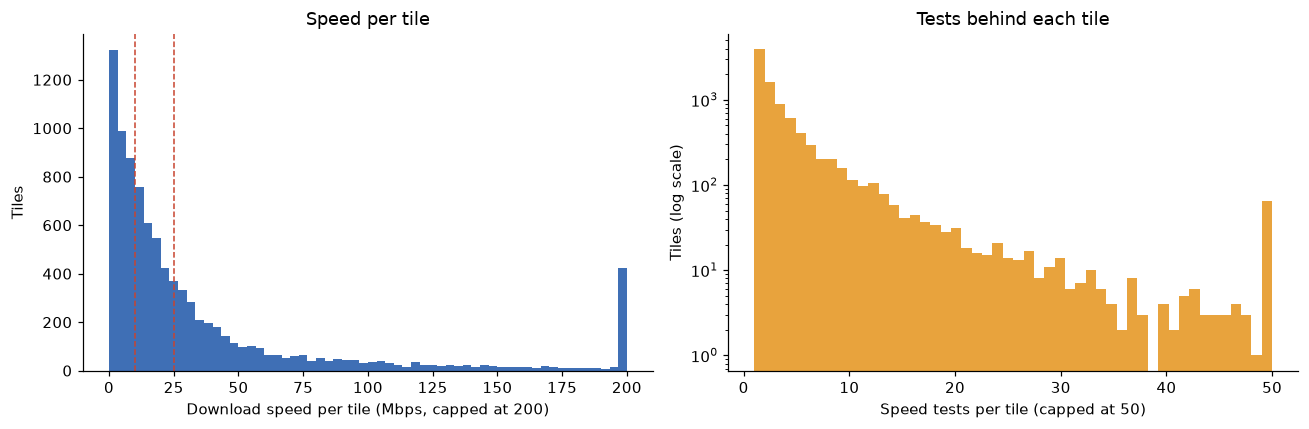

Tiles under 10 Mbps: 34.5%   |   at or above 25 Mbps: 38.2%
Tiles with one test: 42.3%   |   fewer than 5 tests: 75.9%


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(ookla["dl_mbps"].clip(upper=200), bins=60, color=C_COOL)
for value in (BROADBAND_MBPS, HIGH_SPEED_MBPS):
    axes[0].axvline(value, color=C_ACCENT, linestyle="--", linewidth=1)
axes[0].set_xlabel("Download speed per tile (Mbps, capped at 200)")
axes[0].set_ylabel("Tiles")
axes[0].set_title("Speed per tile")

axes[1].hist(ookla["tests"].clip(upper=50), bins=50, color=C_MID)
axes[1].set_yscale("log")
axes[1].set_xlabel("Speed tests per tile (capped at 50)")
axes[1].set_ylabel("Tiles (log scale)")
axes[1].set_title("Tests behind each tile")
plt.tight_layout()
plt.show()

print(f"Tiles under {BROADBAND_MBPS:.0f} Mbps: {(ookla['dl_mbps'] < BROADBAND_MBPS).mean():.1%}   |   "
      f"at or above {HIGH_SPEED_MBPS:.0f} Mbps: {(ookla['dl_mbps'] >= HIGH_SPEED_MBPS).mean():.1%}")
print(f"Tiles with one test: {(ookla['tests'] == 1).mean():.1%}   |   fewer than 5 tests: {(ookla['tests'] < 5).mean():.1%}")

Many tiles rest on one or two tests, so single tiles are noisy and the analysis works at LGA level and above. Tiles exist only where tests were run, so a missing tile is treated as its own class (*unmeasured*), not filled in. The tower file is mostly GSM (2G); OpenCelliD is crowd-sourced, so 3G and 4G towers are probably under-recorded.

In [14]:
def new_map(title, figsize=(9.5, 9)):
    fig, ax = plt.subplots(figsize=figsize)
    states.plot(ax=ax, facecolor="#f4f4f0", edgecolor="#b5b5b0", linewidth=0.5, zorder=1)
    ax.set_title(title, fontsize=13, loc="left")
    ax.set_axis_off()
    return fig, ax

def finish_map(ax, filename=None):
    states.boundary.plot(ax=ax, color="#333333", linewidth=0.7, zorder=6)
    plt.tight_layout()
    if filename:
        plt.savefig(OUT / filename, dpi=170, bbox_inches="tight")
    plt.show()

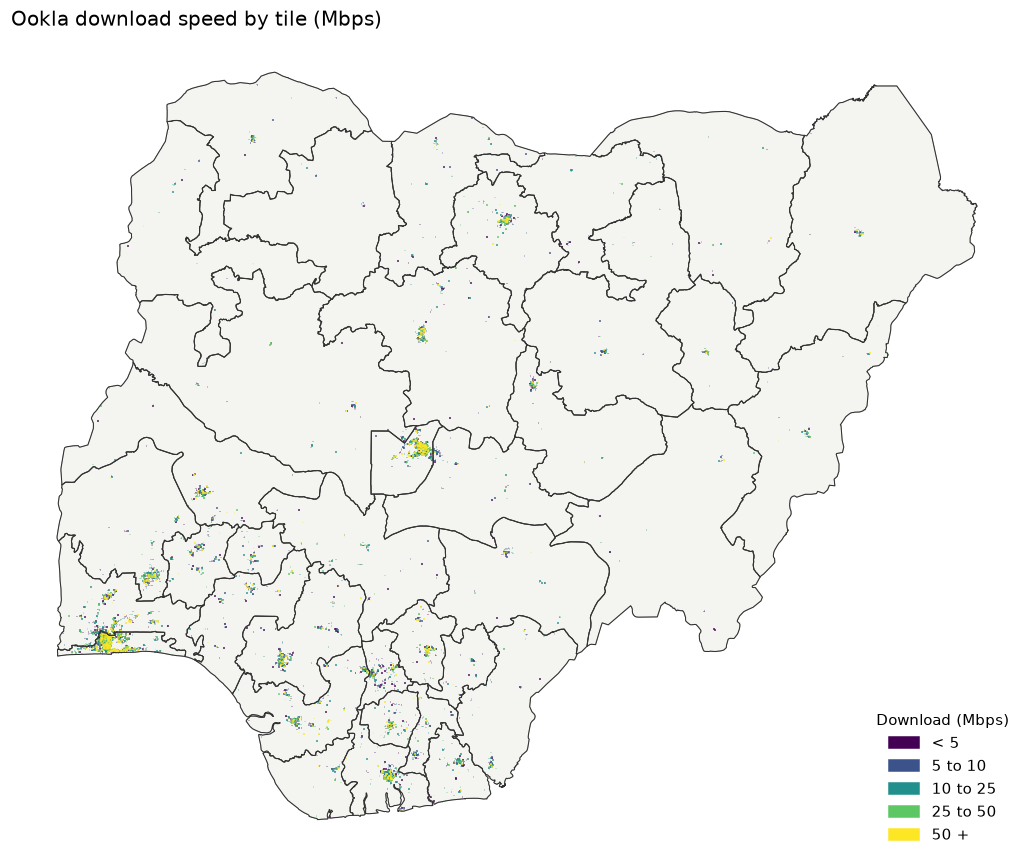

In [15]:
# Map 1: Ookla speed in fixed classes
ookla["speed_class"] = pd.cut(ookla["dl_mbps"], SPEED_BINS, labels=SPEED_LABELS, right=False)
fig, ax = new_map("Ookla download speed by tile (Mbps)")
for label, color in zip(SPEED_LABELS, SPEED_COLORS):
    subset = ookla[ookla["speed_class"] == label]
    if len(subset):
        subset.plot(ax=ax, facecolor=color, edgecolor=color, linewidth=0.4, zorder=2)
ax.legend(handles=[Patch(color=c, label=l) for l, c in zip(SPEED_LABELS, SPEED_COLORS)],
          title="Download (Mbps)", loc="lower right", frameon=False)
finish_map(ax, "map_ookla_speed.png")

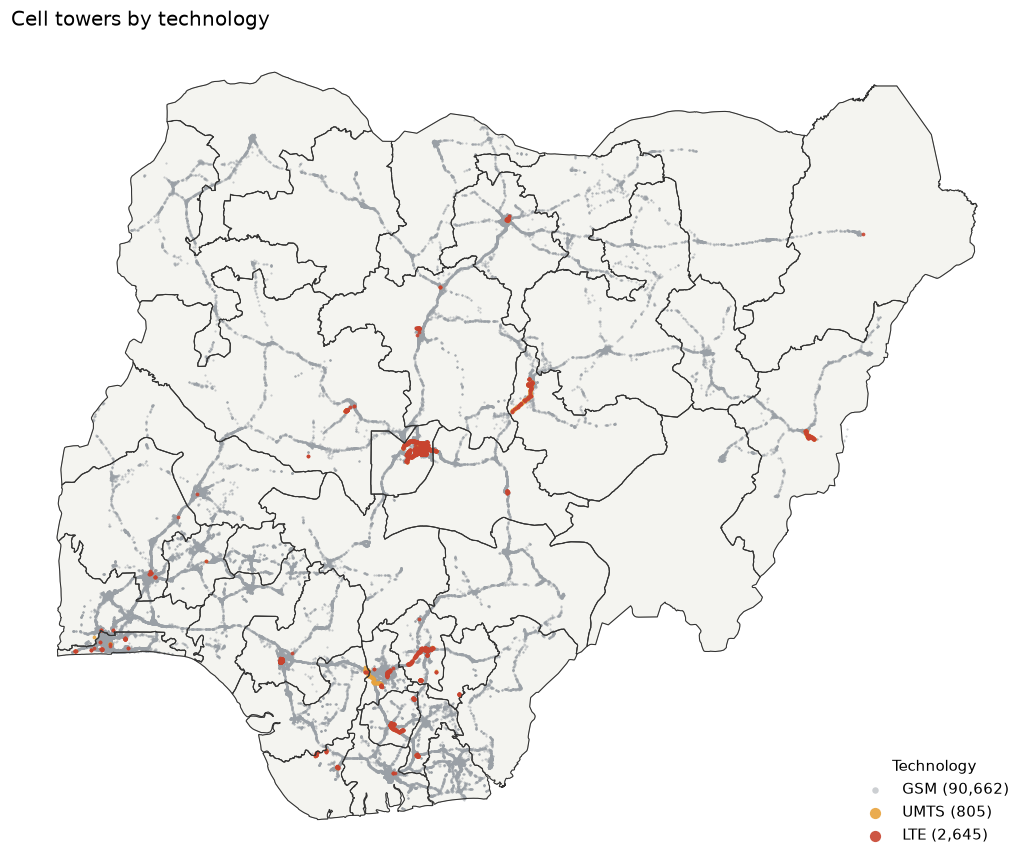

In [16]:
# Map 2: towers by technology
radio_colors = {"GSM": "#9aa0a6", "UMTS": C_MID, "LTE": C_ACCENT, "NR": C_COOL}
fig, ax = new_map("Cell towers by technology")
for radio in ["GSM", "UMTS", "LTE", "NR"]:
    subset = towers[towers["radio"] == radio]
    if len(subset):
        ax.scatter(subset["lon"], subset["lat"], s=2 if radio == "GSM" else 6, color=radio_colors[radio],
                   alpha=0.5 if radio == "GSM" else 0.9, label=f"{radio} ({len(subset):,})", zorder=2, linewidths=0)
ax.legend(markerscale=3, loc="lower right", frameon=False, title="Technology")
finish_map(ax, "map_towers.png")

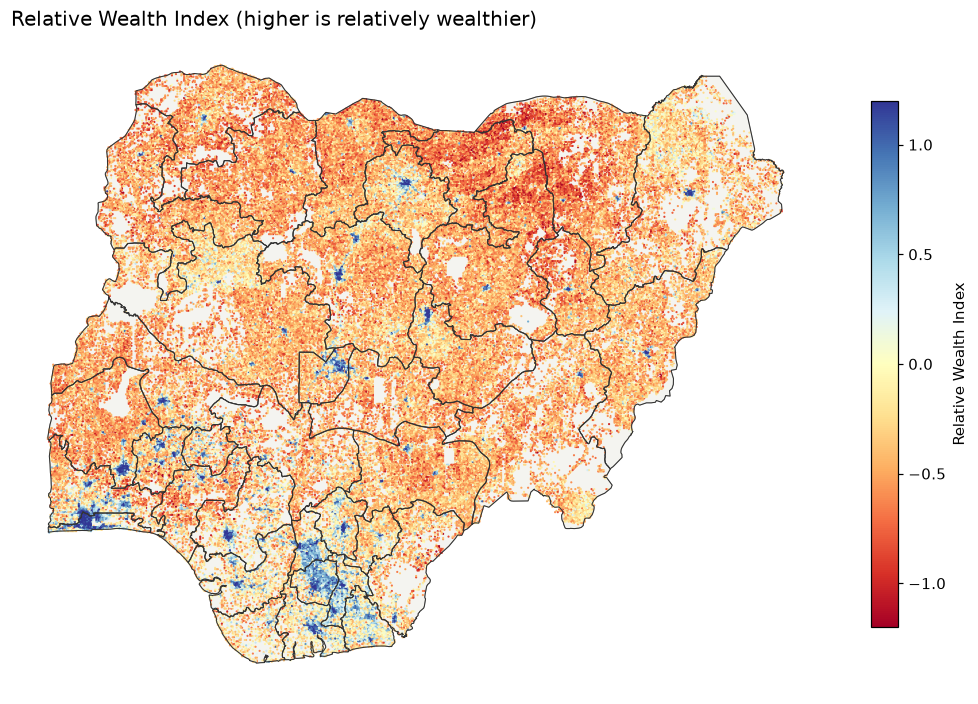

In [17]:
# Map 3: Relative Wealth Index
fig, ax = new_map("Relative Wealth Index (higher is relatively wealthier)")
sc = ax.scatter(wealth["longitude"], wealth["latitude"], c=wealth["rwi"], s=2, cmap="RdYlBu",
                vmin=-1.2, vmax=1.2, zorder=2, linewidths=0)
plt.colorbar(sc, ax=ax, shrink=0.55, label="Relative Wealth Index")
finish_map(ax, "map_wealth.png")

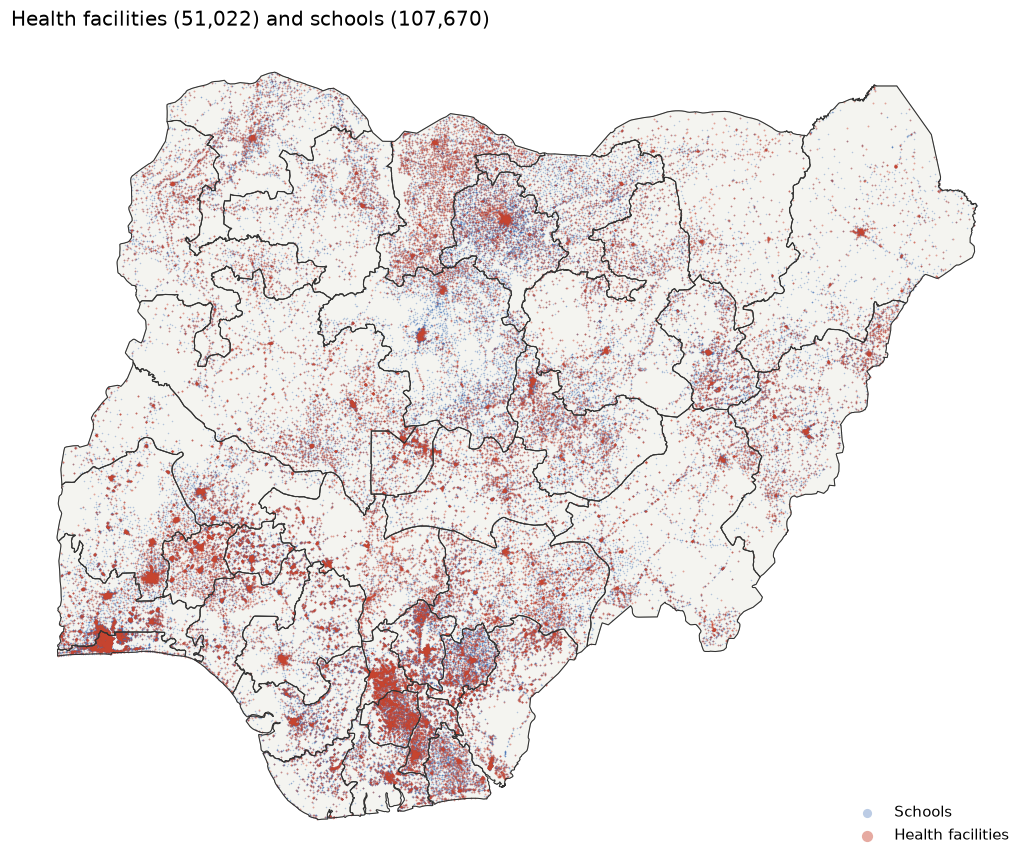

In [18]:
# Map 4: health facilities and schools
fig, ax = new_map(f"Health facilities ({len(health):,}) and schools ({len(schools):,})")
ax.scatter(schools.geometry.x, schools.geometry.y, s=1, color=C_COOL, alpha=0.35, zorder=2, linewidths=0, label="Schools")
ax.scatter(health.geometry.x, health.geometry.y, s=1.5, color=C_ACCENT, alpha=0.45, zorder=3, linewidths=0, label="Health facilities")
ax.legend(markerscale=6, loc="lower right", frameon=False)
finish_map(ax, "map_facilities.png")

## 4. Link settlements to service, towers and wealth

Each settlement block becomes one point and is matched by location:

* **LGA**: the polygon it falls in.
* **Ookla tile**: the tile it falls in. No tile means unmeasured.
* **Nearest tower**: distance in km to the nearest tower, and to the nearest 3G or 4G tower.
* **Wealth**: the nearest Relative Wealth Index point within 5 km.

Results are weighted by buildings, so a town block counts for more than a hamlet. A block is **underserved** when it is unmeasured or measured below the slow-speed threshold.

In [19]:
# Helpers: coordinates in metres, nearest-neighbour trees, tile layer
to_metres = Transformer.from_crs(CRS_GEO, CRS_DIST, always_xy=True)

def to_xy(lon, lat):
    """Degrees to an (n, 2) array of metres."""
    x, y = to_metres.transform(np.asarray(lon, dtype="float64"), np.asarray(lat, dtype="float64"))
    return np.column_stack([x, y])

def first_match(joined, index):
    """Keep one spatial-join match per input point."""
    return joined[~joined.index.duplicated(keep="first")].reindex(index)

tower_xy = to_xy(towers["lon"], towers["lat"])
tree_all = cKDTree(tower_xy)
tree_bb = cKDTree(tower_xy[towers["broadband_capable"].to_numpy()])
tree_rwi = cKDTree(to_xy(wealth["longitude"], wealth["latitude"]))
rwi_values = wealth["rwi"].to_numpy()
tiles = ookla[["dl_mbps", "tests", "geometry"]]

In [20]:
def process_chunk(skip, n):
    """Read n settlement blocks and attach LGA, tile, tower distances and wealth."""
    block = pyogrio.read_dataframe(SETTLEMENT_GPKG, layer=SET_LAYER, columns=SET_COLS,
                                   skip_features=skip, max_features=n)
    if block.crs is None:
        block = block.set_crs(CRS_GEO)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        points = block.geometry.representative_point()
    if points.crs.to_epsg() != 4326:
        points = points.to_crs(CRS_GEO)
    pts = gpd.GeoDataFrame(geometry=points.values, crs=CRS_GEO)

    inside_box = (pts.geometry.x.between(2, 15) & pts.geometry.y.between(4, 14)).mean()
    if inside_box < 0.95:
        raise ValueError("Settlement points do not look like Nigerian longitude/latitude. Check the file's CRS.")

    lga_hit = first_match(gpd.sjoin(pts, lgas[["lga_id", "geometry"]], how="left", predicate="within"), pts.index)
    tile_hit = first_match(gpd.sjoin(pts, tiles, how="left", predicate="within"), pts.index)

    xy = to_xy(pts.geometry.x, pts.geometry.y)
    d_rwi, i_rwi = tree_rwi.query(xy, distance_upper_bound=RWI_MAX_DIST_KM * 1000)
    rwi = np.where(np.isfinite(d_rwi), rwi_values[np.minimum(i_rwi, len(rwi_values) - 1)], np.nan)

    return pd.DataFrame({
        "lga_id": lga_hit["lga_id"].to_numpy(),
        "ext": block["extent_type"].to_numpy(),
        "bld": block["building_count"].to_numpy(dtype="float64"),
        "speed_mbps": tile_hit["dl_mbps"].to_numpy(),
        "tests": tile_hit["tests"].to_numpy(),
        "d_tower_km": tree_all.query(xy)[0] / 1000,
        "d_bb_tower_km": tree_bb.query(xy)[0] / 1000,
        "rwi": rwi,
        "x": xy[:, 0],
        "y": xy[:, 1],
    })

In [21]:
def run_blocks():
    total = set_info["features"]
    if QUICK_RUN:
        total = min(total, 2 * CHUNK)
    parts, started = [], time.time()
    for skip in range(0, total, CHUNK):
        parts.append(process_chunk(skip, min(CHUNK, total - skip)))
        print(f"{skip + len(parts[-1]):>10,} / {total:,} blocks  ({time.time() - started:,.0f} s)")
    return pd.concat(parts, ignore_index=True)

cache_file = CACHE / ("blocks_quick.parquet" if QUICK_RUN else "blocks.parquet")
if cache_file.exists():
    blocks = pd.read_parquet(cache_file)
    print(f"Loaded {cache_file.name}: {len(blocks):,} blocks")
else:
    blocks = run_blocks()
    blocks.to_parquet(cache_file)

   250,000 / 2,546,560 blocks  (57 s)
   500,000 / 2,546,560 blocks  (102 s)
   750,000 / 2,546,560 blocks  (133 s)
 1,000,000 / 2,546,560 blocks  (161 s)
 1,250,000 / 2,546,560 blocks  (186 s)
 1,500,000 / 2,546,560 blocks  (223 s)
 1,750,000 / 2,546,560 blocks  (258 s)
 2,000,000 / 2,546,560 blocks  (290 s)
 2,250,000 / 2,546,560 blocks  (370 s)
 2,500,000 / 2,546,560 blocks  (399 s)
 2,546,560 / 2,546,560 blocks  (404 s)


In [22]:
# Drop blocks outside every LGA (coast and boundary slivers)
outside = blocks["lga_id"].isna()
print(f"Excluded {int(outside.sum()):,} blocks outside all LGAs ({outside.mean():.2%})")
blocks = blocks[~outside].reset_index(drop=True)
blocks["lga_id"] = blocks["lga_id"].astype(int)
blocks["ext"] = blocks["ext"].astype("category")

inside_tile = blocks["speed_mbps"].notna()
print(f"Blocks analysed: {len(blocks):,}   buildings: {blocks['bld'].sum():,.0f}")
print(f"Buildings inside an Ookla tile: {blocks.loc[inside_tile, 'bld'].sum() / blocks['bld'].sum():.1%}")
blocks.head(3)

Excluded 1,235 blocks outside all LGAs (0.05%)
Blocks analysed: 2,545,325   buildings: 63,965,124
Buildings inside an Ookla tile: 9.5%


,lga_id,ext,bld,speed_mbps,tests,d_tower_km,d_bb_tower_km,rwi,x,y
0,662,Hamlet,2.00,NaN,NaN,34.09,41.15,-0.37,"237,099.97","1,102,725.75"
1,662,Hamlet,1.00,NaN,NaN,31.01,38.06,-0.78,"236,437.99","1,099,687.37"
2,653,Small Settlement Area,5.00,NaN,NaN,33.83,47.32,-0.40,"227,333.19","1,108,833.22"


## 5. Health facilities and schools

Each facility is matched to its LGA, its Ookla tile and its nearest tower with the same rules as the settlements. A facility is **underserved** when it sits in no measured tile or in a tile below the slow-speed threshold.

In [23]:
def facility_connectivity(fac):
    """Match a point layer to LGA, Ookla tile and nearest tower."""
    pts = fac[["geometry"]].copy()
    lga_hit = first_match(gpd.sjoin(pts, lgas[["lga_id", "geometry"]], how="left", predicate="within"), pts.index)
    tile_hit = first_match(gpd.sjoin(pts, tiles, how="left", predicate="within"), pts.index)
    xy = to_xy(pts.geometry.x, pts.geometry.y)
    out = pd.DataFrame({
        "lga_id": lga_hit["lga_id"].to_numpy(),
        "speed_mbps": tile_hit["dl_mbps"].to_numpy(),
        "tests": tile_hit["tests"].to_numpy(),
        "d_tower_km": tree_all.query(xy)[0] / 1000,
    }, index=fac.index)
    measured = out["speed_mbps"].notna() & (out["tests"].fillna(0) >= MIN_TESTS)
    out["status"] = np.where(~measured, "Unmeasured", np.where(out["speed_mbps"] < BROADBAND_MBPS, "Slow", "Served"))
    out["underserved"] = out["status"] != "Served"
    return out

In [24]:
health = health.join(facility_connectivity(health))
schools = schools.join(facility_connectivity(schools))

for name, fac in [("Health facilities", health), ("Schools", schools)]:
    shares = fac["status"].value_counts(normalize=True)
    print(f"{name}: {len(fac):,}   " + ",  ".join(f"{k} {v:.1%}" for k, v in shares.items()))

print("\nSchools underserved, by level:")
print(schools.groupby("education")["underserved"].agg(["size", "mean"]).sort_values("size", ascending=False).head(6)
      .rename(columns={"size": "schools", "mean": "underserved_share"}).to_string())

Health facilities: 51,022   Unmeasured 87.7%,  Served 8.6%,  Slow 3.7%
Schools: 107,670   Unmeasured 88.5%,  Served 8.2%,  Slow 3.3%

Schools underserved, by level:
            schools  underserved_share
education                             
Formal       101687               0.92
Integrated     4030               0.93
Religious      1903               0.96
Informal         50               0.98


## 6. Population by LGA

Population is the sum of the WorldPop 100 m raster inside each LGA. Where population is needed for underserved people, it is shared in proportion to buildings inside the LGA (an LGA with 30% of its buildings underserved is assumed to have 30% of its people underserved).

In [25]:
def lga_population(raster_path):
    """Sum raster cell values inside each LGA polygon."""
    with rasterio.open(raster_path) as src:
        geoms = lgas.to_crs(src.crs).geometry
    result = zonal_stats(list(geoms), str(raster_path), stats=["sum"], all_touched=False)
    return pd.Series([r["sum"] or 0 for r in result], index=pd.Index(lgas["lga_id"], name="lga_id"), name="population")

pop_cache = CACHE / "lga_population.csv"
if pop_cache.exists():
    population = pd.read_csv(pop_cache, index_col="lga_id")["population"]
else:
    population = lga_population(POP_RASTER)
    population.to_csv(pop_cache)

print(f"Total population in the LGAs: {population.sum():,.0f}")
print(f"LGAs with zero population: {int((population == 0).sum())}")

Total population in the LGAs: 211,661,940
LGAs with zero population: 0


## 7. Does service follow settlement size?

Buildings are split by settlement type into served, slow and unmeasured.

In [26]:
def service_flags(b, min_tests=MIN_TESTS, bb_mbps=BROADBAND_MBPS):
    """Boolean arrays for measured, slow and underserved blocks."""
    speed = b["speed_mbps"].to_numpy()
    tests = b["tests"].fillna(0).to_numpy()
    measured = ~np.isnan(speed) & (tests >= min_tests)
    slow = measured & (np.nan_to_num(speed, nan=np.inf) < bb_mbps)
    return measured, slow, (~measured) | slow

def hierarchy_table(b, min_tests=MIN_TESTS):
    """Share of buildings served, slow and unmeasured, by settlement type."""
    measured, slow, _ = service_flags(b, min_tests)
    w = b["bld"].to_numpy(dtype="float64")
    df = pd.DataFrame({
        "ext": b["ext"].astype(object).to_numpy(), "blocks": 1, "buildings": w,
        "unmeasured": w * ~measured, "slow": w * slow, "served": w * (measured & ~slow),
        "w_dist": w * b["d_tower_km"].to_numpy(),
    })
    g = df.groupby("ext").sum()
    order = [e for e in ["Hamlet", "Small Settlement Area", "Built-up Area"] if e in g.index]
    g = g.reindex(order + [e for e in g.index if e not in order])
    out = pd.DataFrame({"blocks": g["blocks"], "buildings": g["buildings"]})
    for col in ["unmeasured", "slow", "served"]:
        out[f"{col}_share"] = g[col] / g["buildings"]
    out["mean_dist_tower_km"] = g["w_dist"] / g["buildings"]
    return out

                       blocks  buildings  unmeasured_share  slow_share  served_share  mean_dist_tower_km
ext                                                                                                     
Hamlet                626,939  5,886,124              1.00        0.00          0.00               25.08
Small Settlement Area 967,436 23,464,261              1.00        0.00          0.00               20.45
Built-up Area         950,950 34,614,739              0.83        0.06          0.12                6.59


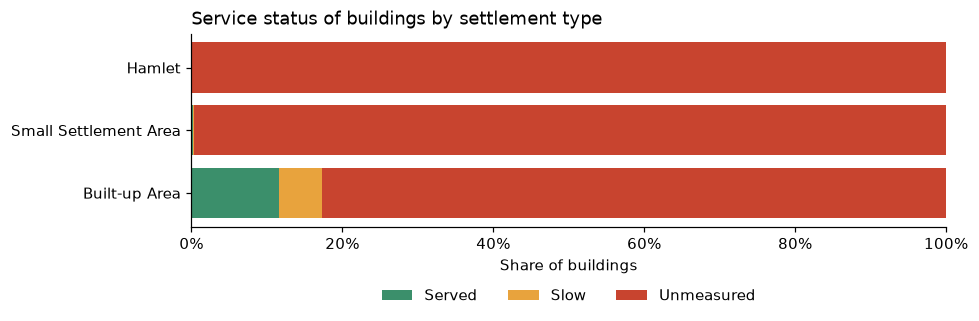

In [27]:
hier = hierarchy_table(blocks)
print(hier.to_string(formatters={"blocks": "{:,.0f}".format, "buildings": "{:,.0f}".format}))

fig, ax = plt.subplots(figsize=(9, 3.2))
left = np.zeros(len(hier))
for col, color, label in [("served_share", C_OK, "Served"), ("slow_share", C_MID, "Slow"), ("unmeasured_share", C_ACCENT, "Unmeasured")]:
    ax.barh(hier.index, hier[col], left=left, color=color, label=label)
    left += hier[col].to_numpy()
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Share of buildings")
ax.set_title("Service status of buildings by settlement type", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3, frameon=False)
plt.tight_layout()
plt.savefig(OUT / "chart_settlement_types.png", dpi=170, bbox_inches="tight")
plt.show()

## 8. LGA indicators

Block results are combined per LGA, weighted by buildings, and joined with population and facility counts.

In [28]:
def build_lga_table(b, min_tests=MIN_TESTS):
    """Service, tower and wealth indicators per LGA (weighted by buildings)."""
    measured, slow, _ = service_flags(b, min_tests)
    w = b["bld"].to_numpy(dtype="float64")
    rwi = b["rwi"].to_numpy()
    has_rwi = ~np.isnan(rwi)
    d = pd.DataFrame({
        "lga_id": b["lga_id"].to_numpy(), "blocks": 1, "bld": w,
        "bld_unmeasured": w * ~measured, "bld_slow": w * slow, "bld_measured": w * measured,
        "w_speed": np.where(measured, w * np.nan_to_num(b["speed_mbps"].to_numpy()), 0.0),
        "w_dist": w * b["d_tower_km"].to_numpy(),
        "bld_far": w * (b["d_tower_km"].to_numpy() > FAR_FROM_TOWER_KM),
        "w_rwi": np.where(has_rwi, w * np.nan_to_num(rwi), 0.0),
        "bld_rwi": np.where(has_rwi, w, 0.0),
    })
    g = d.groupby("lga_id").sum()
    out = pd.DataFrame(index=g.index)
    out["buildings"] = g["bld"]
    out["unmeasured_share"] = g["bld_unmeasured"] / g["bld"]
    out["slow_share"] = g["bld_slow"] / g["bld"]
    out["underserved_share"] = out["unmeasured_share"] + out["slow_share"]
    out["underserved_buildings"] = g["bld_unmeasured"] + g["bld_slow"]
    out["mean_speed_mbps"] = g["w_speed"] / g["bld_measured"].replace(0, np.nan)
    out["mean_dist_tower_km"] = g["w_dist"] / g["bld"]
    out["far_share"] = g["bld_far"] / g["bld"]
    out["mean_rwi"] = g["w_rwi"] / g["bld_rwi"].replace(0, np.nan)
    return out

def add_context(t, ctx):
    """Add population and facility columns, and underserved people."""
    out = t.join(ctx, how="left")
    out["underserved_pop"] = out["population"] * out["underserved_share"]
    return out

def pct_rank(s):
    """Percentile rank, 0 to 1 (ties share the average)."""
    return s.rank(pct=True, method="average")

In [29]:
def lga_counts(fac, value=None):
    """Facilities (or a summed column) per LGA, aligned to every LGA."""
    f = fac.dropna(subset=["lga_id"])
    key = f["lga_id"].astype(int)
    s = f.groupby(key).size() if value is None else f.groupby(key)[value].sum()
    return s.reindex(lgas["lga_id"]).fillna(0).set_axis(pd.Index(lgas["lga_id"], name="lga_id"))

ctx = pd.DataFrame(index=pd.Index(lgas["lga_id"], name="lga_id"))
ctx["population"] = population
ctx["health"] = lga_counts(health)
ctx["health_underserved"] = lga_counts(health[health["underserved"]])
ctx["schools"] = lga_counts(schools)
ctx["schools_underserved"] = lga_counts(schools[schools["underserved"]])
ctx["students"] = lga_counts(schools, "student_ct")
ctx["students_underserved"] = lga_counts(schools[schools["underserved"]], "student_ct")
ctx["institutions"] = ctx["health"] + ctx["schools"]
ctx["institutions_underserved"] = ctx["health_underserved"] + ctx["schools_underserved"]
ctx["institution_share"] = ctx["institutions_underserved"] / ctx["institutions"].replace(0, np.nan)
ctx.describe().T[["mean", "max"]]

,mean,max
population,"273,465.04","3,288,690.00"
health,65.92,316.00
health_underserved,60.26,237.00
schools,139.11,"1,546.00"
schools_underserved,127.76,792.00
students,"2,399.31","117,840.00"
students_underserved,"1,996.15","64,698.00"
institutions,205.02,"1,862.00"
institutions_underserved,188.02,969.00
institution_share,0.95,1.00


In [30]:
table = add_context(build_lga_table(blocks), ctx)

# Ookla's own tile statistics per LGA, for reference
tile_points = gpd.GeoDataFrame(ookla[["dl_mbps", "tests"]], geometry=gpd.points_from_xy(ookla["tile_x"], ookla["tile_y"]), crs=CRS_GEO)
tile_join = gpd.sjoin(tile_points, lgas[["lga_id", "geometry"]], how="left", predicate="within")
tile_join = tile_join[~tile_join.index.duplicated(keep="first")].dropna(subset=["lga_id"])
tile_stats = tile_join.groupby("lga_id").agg(tiles=("dl_mbps", "size"), tests=("tests", "sum"), tile_speed_median=("dl_mbps", "median"))
tile_stats.index = tile_stats.index.astype(int)

lga = lgas.merge(table.join(tile_stats, how="left").reset_index(), on="lga_id", how="left")
lga[["tiles", "tests"]] = lga[["tiles", "tests"]].fillna(0)
print(f"LGAs with settlement data: {lga['buildings'].notna().sum()} of {len(lga)};  LGAs with no Ookla tile at all: {int((lga['tiles'] == 0).sum())}")

LGAs with settlement data: 774 of 774;  LGAs with no Ookla tile at all: 234


### Is connectivity related to wealth?

Spearman rank correlation between each LGA's mean wealth index and its underserved share.

Spearman correlation across 774 LGAs: -0.69 (p = 4.5e-112)


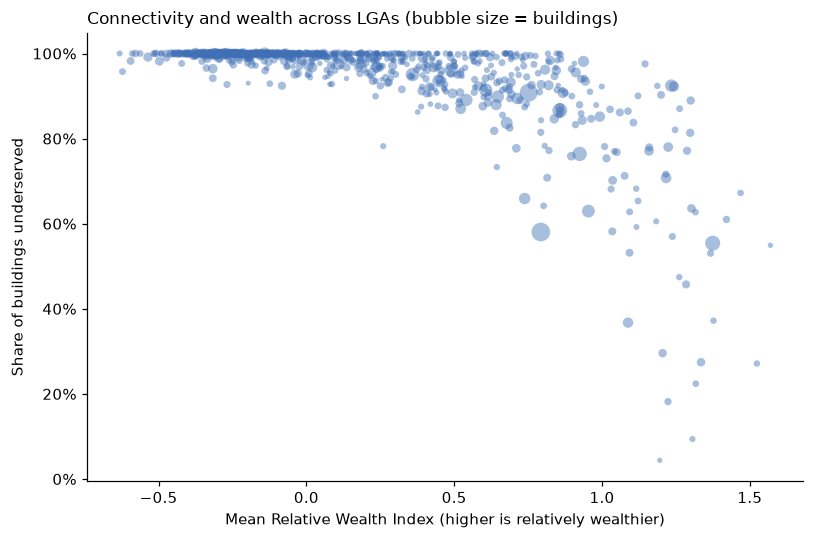

In [31]:
valid = lga.dropna(subset=["underserved_share", "mean_rwi"])
rho, p_value = stats.spearmanr(valid["mean_rwi"], valid["underserved_share"])
print(f"Spearman correlation across {len(valid)} LGAs: {rho:.2f} (p = {p_value:.2g})")

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(valid["mean_rwi"], valid["underserved_share"], s=10 + 140 * valid["buildings"] / valid["buildings"].max(),
           color=C_COOL, alpha=0.45, linewidths=0)
ax.set_xlabel("Mean Relative Wealth Index (higher is relatively wealthier)")
ax.set_ylabel("Share of buildings underserved")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Connectivity and wealth across LGAs (bubble size = buildings)", loc="left", fontsize=11)
plt.tight_layout()
plt.savefig(OUT / "chart_wealth_vs_service.png", dpi=170, bbox_inches="tight")
plt.show()

## 9. Digital Inclusion Priority Index (LGA)

Five components, each turned into a percentile rank among LGAs (0 to 1, higher is worse) and combined with fixed weights.

* **Service gap (0.30):** share of buildings that are unmeasured or slow.
* **Exposure (0.20):** number of people in those underserved buildings.
* **Infrastructure gap (0.15):** average distance to the nearest tower.
* **Need (0.20):** low wealth (inverse of the Relative Wealth Index).
* **Institution gap (0.15):** share of health facilities and schools that are underserved.

LGAs missing a wealth or institution value get the neutral rank 0.5. The weights are a judgement, so section 9.1 tests how much they matter.

In [32]:
def priority_index(t, weights=WEIGHTS):
    """Component ranks and the 0 to 100 priority score for a table of indicators."""
    comp = pd.DataFrame(index=t.index)
    comp["service_gap"] = pct_rank(t["underserved_share"])
    comp["exposure"] = pct_rank(t["underserved_pop"])
    comp["infra_gap"] = pct_rank(t["mean_dist_tower_km"])
    comp["need"] = (1 - pct_rank(t["mean_rwi"])).fillna(0.5)
    comp["institution_gap"] = pct_rank(t["institution_share"]).fillna(0.5)
    score = sum(weights[k] * comp[k] for k in weights) / sum(weights.values())
    return comp, 100 * score

def rank_classes(score):
    """Five equal-sized classes by rank."""
    return pd.qcut(score.rank(method="first"), 5, labels=QUINTILES)

In [33]:
scored = lga[lga["buildings"].notna() & (lga["buildings"] > 0)].copy()
components, scored["priority"] = priority_index(scored)
scored = scored.join(components)
scored["priority_class"] = rank_classes(scored["priority"])
scored["priority_rank"] = scored["priority"].rank(ascending=False, method="first").astype(int)
scored["in_priority_set"] = scored["priority"] >= scored["priority"].quantile(PRIORITY_QUANTILE)
print(f"{len(scored)} LGAs scored; priority set (top {1 - PRIORITY_QUANTILE:.0%}): {int(scored['in_priority_set'].sum())} LGAs")

view = scored.sort_values("priority", ascending=False).head(15)
view[["label", "zone", "priority", "population", "underserved_share", "mean_dist_tower_km", "mean_rwi"]].rename(columns={
    "label": "LGA", "zone": "Zone", "priority": "Score", "population": "Population",
    "underserved_share": "Underserved", "mean_dist_tower_km": "Tower km", "mean_rwi": "Mean RWI"}).reset_index(drop=True)

774 LGAs scored; priority set (top 20%): 155 LGAs


,LGA,Zone,Score,Population,Underserved,Tower km,Mean RWI
0,Maru (Zamfara),North West,86.98,"530,530.12",1.00,51.43,-0.37
1,Alkaleri (Bauchi),North East,85.50,"579,107.81",1.00,24.57,-0.35
2,Katsina-Ala (Benue),North Central,84.92,"514,071.38",1.00,30.23,-0.31
3,Bukkuyum (Zamfara),North West,84.48,"344,830.47",1.00,54.85,-0.40
4,Ningi (Bauchi),North East,84.44,"614,819.25",1.00,25.48,-0.28
5,Wasagu-Danko (Kebbi),North West,83.69,"460,359.12",1.00,30.43,-0.27
6,Kauru (Kaduna),North West,83.43,"365,002.00",1.00,20.78,-0.39
7,Kafin Hausa (Jigawa),North West,83.04,"466,632.91",1.00,10.22,-0.43
8,Ganjuwa (Bauchi),North East,82.64,"501,349.09",1.00,9.86,-0.38
9,Gummi (Zamfara),North West,82.63,"325,642.25",1.00,41.68,-0.33


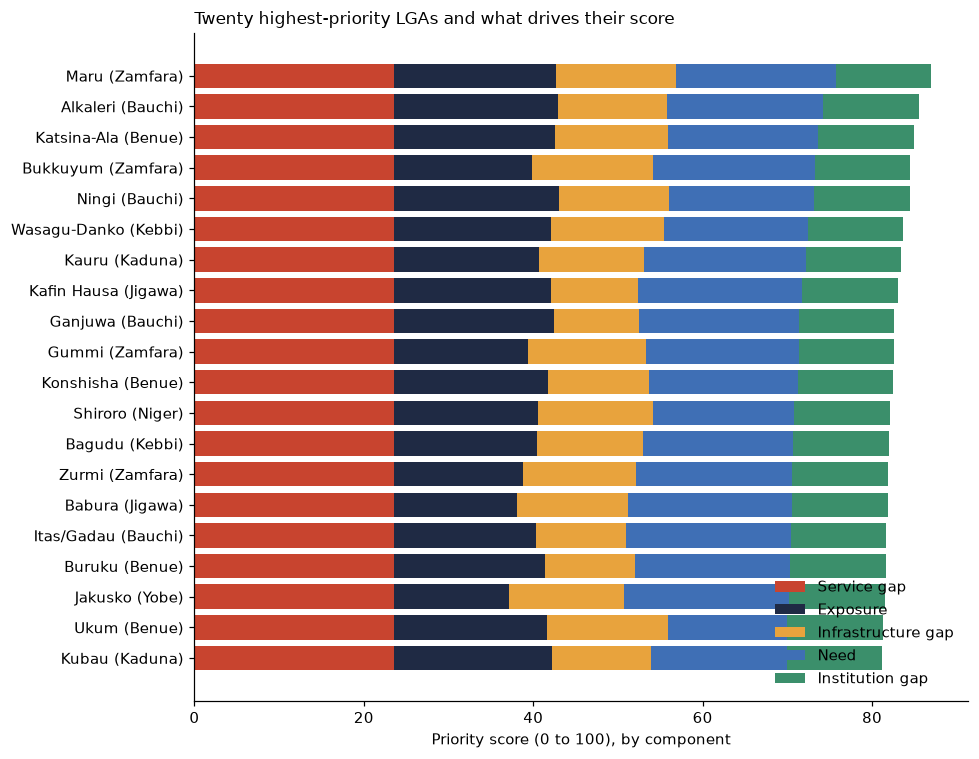

In [34]:
top20 = scored.sort_values("priority").tail(20)
labels = {"service_gap": "Service gap", "exposure": "Exposure", "infra_gap": "Infrastructure gap",
          "need": "Need", "institution_gap": "Institution gap"}
colors = {"service_gap": C_ACCENT, "exposure": C_DARK, "infra_gap": C_MID, "need": C_COOL, "institution_gap": C_OK}

fig, ax = plt.subplots(figsize=(9, 7))
left = np.zeros(len(top20))
for k in labels:
    part = top20[k].to_numpy() * WEIGHTS[k] * 100 / sum(WEIGHTS.values())
    ax.barh(top20["label"], part, left=left, color=colors[k], label=labels[k])
    left += part
ax.set_xlabel("Priority score (0 to 100), by component")
ax.set_title("Twenty highest-priority LGAs and what drives their score", loc="left", fontsize=11)
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.savefig(OUT / "chart_top20_components.png", dpi=170, bbox_inches="tight")
plt.show()

### 9.1 Robustness

Two checks that the ranking does not hinge on the weights:

1. **Alternative versions:** equal weights, each component removed in turn, exposure counted in buildings instead of people, and a stricter rule that only uses tiles with three or more tests. Each is compared with the baseline (Spearman correlation, and overlap of the top 50 LGAs).
2. **Random weights:** 1,000 random weightings; for each LGA, how often it lands in the top 10%.

In [35]:
def scenario_table(t_base, b, ctx, top_n=50):
    """Compare the baseline ranking with alternative versions."""
    base = priority_index(t_base)[1]
    n = len(WEIGHTS)
    versions = {"Equal weights": priority_index(t_base, {k: 1 / n for k in WEIGHTS})[1]}
    for k in WEIGHTS:
        versions[f"Without {k.replace('_', ' ')}"] = priority_index(t_base, {m: (0.0 if m == k else v) for m, v in WEIGHTS.items()})[1]
    versions["Exposure in buildings, not people"] = priority_index(t_base.assign(underserved_pop=t_base["underserved_buildings"]))[1]
    strict = add_context(build_lga_table(b, min_tests=3), ctx).reindex(t_base["lga_id"].to_numpy())
    strict.index = t_base.index
    versions["Tiles with 3+ tests only"] = priority_index(strict)[1]

    base_top = set(base.nlargest(top_n).index)
    rows = [(name, stats.spearmanr(base, s, nan_policy="omit")[0], len(base_top & set(s.nlargest(top_n).index)))
            for name, s in versions.items()]
    return pd.DataFrame(rows, columns=["Version", "Spearman vs baseline", f"Overlap in top {top_n}"]).set_index("Version")

def top_decile_frequency(t, n_draws=1000, seed=RANDOM_SEED):
    """Share of random weightings in which each LGA is in the top 10%."""
    comp, _ = priority_index(t)
    draws = np.random.default_rng(seed).dirichlet(np.ones(len(WEIGHTS)), size=n_draws)
    scores = comp[list(WEIGHTS)].to_numpy() @ draws.T
    ranks = (-scores).argsort(axis=0).argsort(axis=0) + 1
    return pd.Series((ranks <= int(0.10 * len(comp))).mean(axis=1), index=comp.index, name="top_decile_freq")

In [36]:
robustness = scenario_table(scored, blocks, ctx)
print(robustness.to_string())

scored["top_decile_freq"] = top_decile_frequency(scored)
n_top = int(0.10 * len(scored))
robust_top = int((scored.nlargest(n_top, "priority")["top_decile_freq"] >= 0.80).sum())
print(f"\n{robust_top} of the {n_top} highest-scoring LGAs are in the top 10% under at least 80% of random weightings.")

                                   Spearman vs baseline  Overlap in top 50
Version                                                                   
Equal weights                                      1.00                 46
Without service gap                                0.96                 43
Without exposure                                   0.96                 16
Without infra gap                                  0.99                 40
Without need                                       0.98                 39
Without institution gap                            0.99                 49
Exposure in buildings, not people                  0.98                 34
Tiles with 3+ tests only                           0.97                 45

26 of the 77 highest-scoring LGAs are in the top 10% under at least 80% of random weightings.


## 10. Zones, states and LGAs

LGA results are combined into states and geopolitical zones (shares are weighted by buildings, people and facilities are summed). The same index is applied at each level, so the priority list reads top-down: zone, then state, then the LGAs inside the top states.

In [37]:
SUM_COLS = ["buildings", "underserved_buildings", "population", "underserved_pop", "health", "health_underserved",
            "schools", "schools_underserved", "students", "students_underserved"]

def rollup(df, by):
    """Combine LGA rows into larger areas (states or zones)."""
    b = df["buildings"]
    measured_b = b * (1 - df["unmeasured_share"])
    has_speed, has_rwi = df["mean_speed_mbps"].notna(), df["mean_rwi"].notna()
    parts = df[SUM_COLS].copy()
    parts["unmeasured_b"] = b * df["unmeasured_share"]
    parts["slow_b"] = b * df["slow_share"]
    parts["far_b"] = b * df["far_share"]
    parts["w_dist"] = b * df["mean_dist_tower_km"]
    parts["w_speed"] = (measured_b * df["mean_speed_mbps"]).where(has_speed, 0)
    parts["b_speed"] = measured_b.where(has_speed, 0)
    parts["w_rwi"] = (b * df["mean_rwi"]).where(has_rwi, 0)
    parts["b_rwi"] = b.where(has_rwi, 0)
    parts["n_lgas"] = 1
    g = parts.groupby(df[by]).sum()

    out = g[SUM_COLS + ["n_lgas"]].copy()
    out["unmeasured_share"] = g["unmeasured_b"] / g["buildings"]
    out["slow_share"] = g["slow_b"] / g["buildings"]
    out["underserved_share"] = out["underserved_buildings"] / out["buildings"]
    out["far_share"] = g["far_b"] / g["buildings"]
    out["mean_dist_tower_km"] = g["w_dist"] / g["buildings"]
    out["mean_speed_mbps"] = g["w_speed"] / g["b_speed"].replace(0, np.nan)
    out["mean_rwi"] = g["w_rwi"] / g["b_rwi"].replace(0, np.nan)
    out["institutions"] = out["health"] + out["schools"]
    out["institutions_underserved"] = out["health_underserved"] + out["schools_underserved"]
    out["institution_share"] = out["institutions_underserved"] / out["institutions"].replace(0, np.nan)
    return out

In [38]:
def score_area(tbl):
    """Add the priority score, class and rank to a rolled-up table."""
    comp, tbl["priority"] = priority_index(tbl)
    tbl = tbl.join(comp)
    tbl["priority_class"] = rank_classes(tbl["priority"])
    tbl["priority_rank"] = tbl["priority"].rank(ascending=False, method="first").astype(int)
    return tbl.sort_values("priority", ascending=False)

zone_tbl = score_area(rollup(scored, "zone"))

state_tbl = rollup(scored, "statecode")
state_tbl["state"] = states.set_index("statecode")["statename"]
state_tbl["zone"] = states.set_index("statecode")["zone"]
state_tbl = score_area(state_tbl)

scored["state_rank"] = scored["statecode"].map(state_tbl["priority_rank"])
scored["zone_rank"] = scored["zone"].map(zone_tbl["priority_rank"])

In [39]:
# Zones: six units, so read the score together with the underserved share and people
zone_tbl[["priority", "underserved_share", "underserved_pop", "population", "mean_dist_tower_km", "mean_rwi", "institution_share"]].rename(columns={
    "priority": "Score", "underserved_share": "Underserved share", "underserved_pop": "Underserved people",
    "population": "Population", "mean_dist_tower_km": "Tower km", "mean_rwi": "Mean RWI", "institution_share": "Institutions underserved"})

,Score,Underserved share,Underserved people,Population,Tower km,Mean RWI,Institutions underserved
zone,,,,,,,
North East,86.67,0.99,"28,486,831.80","28,857,018.94",29.88,-0.02,0.99
North West,80.83,0.97,"50,136,718.91","51,923,074.27",13.63,-0.00,0.97
North Central,60.83,0.94,"30,262,433.52","32,540,765.86",14.45,0.12,0.96
South East,39.17,0.94,"22,416,564.81","23,649,086.15",3.86,0.57,0.93
South South,35.83,0.89,"27,926,519.01","31,185,211.46",4.13,0.52,0.92
South West,26.67,0.83,"35,917,958.33","43,506,783.07",2.53,0.72,0.77


In [40]:
# States: top 15
state_tbl.head(15)[["state", "zone", "priority", "underserved_share", "underserved_pop", "population", "n_lgas"]].rename(columns={
    "priority": "Score", "underserved_share": "Underserved share", "underserved_pop": "Underserved people",
    "population": "Population", "n_lgas": "LGAs"}).reset_index(drop=True)

,state,zone,Score,Underserved share,Underserved people,Population,LGAs
0,Zamfara,North West,86.62,1.00,"4,746,855.42","4,768,289.31",14
1,Bauchi,North East,86.49,0.99,"6,982,231.19","7,037,966.84",20
2,Jigawa,North West,81.08,0.99,"5,828,897.24","5,923,783.27",27
3,Benue,North Central,80.27,0.99,"5,872,848.21","5,960,096.12",23
4,Katsina,North West,79.59,0.98,"8,214,779.04","8,352,530.08",34
5,Sokoto,North West,79.46,0.98,"5,074,317.04","5,173,259.20",23
6,Yobe,North East,77.57,0.99,"3,884,201.26","3,910,412.70",17
7,Kebbi,North West,77.30,0.99,"4,593,061.55","4,638,506.55",21
8,Borno,North East,76.62,0.98,"6,717,248.96","6,825,036.21",27
9,Taraba,North East,74.19,0.99,"3,057,811.70","3,079,111.66",16


In [41]:
# Drill-down: the five highest-ranked LGAs inside each of the five highest-ranked states
top_states = state_tbl.head(5).index
drill = (scored[scored["statecode"].isin(top_states)]
         .sort_values(["state_rank", "priority"], ascending=[True, False])
         .groupby("statecode", sort=False).head(5))
drill[["statename", "lganame", "priority", "population", "underserved_share", "mean_dist_tower_km"]].rename(columns={
    "statename": "State", "lganame": "LGA", "priority": "Score", "population": "Population",
    "underserved_share": "Underserved share", "mean_dist_tower_km": "Tower km"}).reset_index(drop=True)

,State,LGA,Score,Population,Underserved share,Tower km
0,Zamfara,Maru,86.98,"530,530.12",1.00,51.43
1,Zamfara,Bukkuyum,84.48,"344,830.47",1.00,54.85
2,Zamfara,Gummi,82.63,"325,642.25",1.00,41.68
3,Zamfara,Zurmi,81.85,"311,902.78",1.00,30.16
4,Zamfara,Bungudu,80.36,"561,085.81",1.00,9.41
5,Bauchi,Alkaleri,85.50,"579,107.81",1.00,24.57
6,Bauchi,Ningi,84.44,"614,819.25",1.00,25.48
7,Bauchi,Ganjuwa,82.64,"501,349.09",1.00,9.86
8,Bauchi,Itas/Gadau,81.63,"355,899.00",1.00,11.35
9,Bauchi,Tafawa-Balewa,80.37,"359,432.00",1.00,13.82


## 11. Spatial clusters

Global Moran's I tests whether LGAs with similar scores sit next to each other. Local Moran's I (LISA) finds the clusters. A **priority cluster** is an LGA with a high score and high-scoring neighbours, significant at p < 0.05 (999 permutations).

In [42]:
from libpysal.weights import Queen
from esda.moran import Moran, Moran_Local

geo = scored.reset_index(drop=True)
weights_q = Queen.from_dataframe(geo, silence_warnings=True)    # neighbours share a boundary
weights_q.transform = "R"
y = geo["priority"].to_numpy()

np.random.seed(RANDOM_SEED)
moran = Moran(y, weights_q, permutations=999)
print(f"Global Moran's I = {moran.I:.3f} (pseudo p = {moran.p_sim:.3f})")

Global Moran's I = 0.593 (pseudo p = 0.001)


In [43]:
np.random.seed(RANDOM_SEED)
lisa = Moran_Local(y, weights_q, permutations=999)

sig = lisa.p_sim < 0.05
cluster = np.full(len(geo), "Not significant", dtype=object)
cluster[sig & (lisa.q == 1)] = "High-High (priority cluster)"
cluster[sig & (lisa.q == 3)] = "Low-Low"
cluster[sig & (lisa.q == 2)] = "Low-High outlier"
cluster[sig & (lisa.q == 4)] = "High-Low outlier"
scored["cluster"] = cluster          # same row order as geo
print(scored["cluster"].value_counts().to_string())

cluster
Not significant                 446
High-High (priority cluster)    191
Low-Low                         112
Low-High outlier                 17
High-Low outlier                  8


## 12. Which towers to upgrade first

Inside the priority LGAs, underserved people are added up in 1 km cells. Candidate sites are existing non-LTE towers in those LGAs, each assumed to serve cells within 3 km. Sites are picked one at a time, always taking the tower that reaches the most people not yet reached (the standard greedy method for maximum coverage). People beyond reach of every candidate need new sites, and are reported separately.

In [44]:
def demand_cells(b, mask, col="people", cell_m=CELL_KM * 1000):
    """Add up a column over the selected blocks in square cells."""
    gx = np.floor(b["x"].to_numpy()[mask] / cell_m).astype(np.int64)
    gy = np.floor(b["y"].to_numpy()[mask] / cell_m).astype(np.int64)
    w = b[col].to_numpy(dtype="float64")[mask]
    cells = pd.DataFrame({"gx": gx, "gy": gy, "w": w}).groupby(["gx", "gy"], as_index=False)["w"].sum()
    cells["x"] = (cells["gx"] + 0.5) * cell_m
    cells["y"] = (cells["gy"] + 0.5) * cell_m
    return cells

def greedy_sites(cand_xy, cell_xy, cell_w, radius_m, k):
    """Greedy maximum coverage. Returns chosen candidates, their gains and the weight within reach."""
    nbrs = [np.asarray(n, dtype=np.int64) for n in cKDTree(cell_xy).query_ball_point(cand_xy, r=radius_m)]
    reachable = np.zeros(len(cell_xy), dtype=bool)
    for n in nbrs:
        reachable[n] = True
    covered = np.zeros(len(cell_xy), dtype=bool)
    heap = [(-cell_w[n].sum(), i) for i, n in enumerate(nbrs) if len(n)]
    heapq.heapify(heap)
    chosen, gains = [], []
    while heap and len(chosen) < k:
        _, i = heapq.heappop(heap)
        gain = cell_w[nbrs[i]][~covered[nbrs[i]]].sum()
        if heap and gain < -heap[0][0] - 1e-9:       # value is out of date: put it back
            heapq.heappush(heap, (-gain, i))
            continue
        if gain <= 0:
            break
        covered[nbrs[i]] = True
        chosen.append(i)
        gains.append(gain)
    return chosen, gains, cell_w[reachable].sum()

In [45]:
# People per building in each LGA turn building counts into people
people_per_building = ctx["population"] / table["buildings"]
blocks["people"] = blocks["bld"] * blocks["lga_id"].map(people_per_building).fillna(0).to_numpy()

# Which LGA each tower is in
tower_pts = gpd.GeoDataFrame(geometry=gpd.points_from_xy(towers["lon"], towers["lat"]), crs=CRS_GEO)
towers["lga_id"] = first_match(gpd.sjoin(tower_pts, lgas[["lga_id", "geometry"]], how="left", predicate="within"),
                               tower_pts.index)["lga_id"].to_numpy()

priority_ids = set(scored.loc[scored["in_priority_set"], "lga_id"])
_, _, underserved_mask = service_flags(blocks)
in_priority = blocks["lga_id"].isin(priority_ids).to_numpy()

cells = demand_cells(blocks, underserved_mask & in_priority)
cand = towers[towers["lga_id"].isin(priority_ids) & (towers["radio"] != "LTE")].copy()
print(f"Underserved people in priority LGAs: {cells['w'].sum():,.0f}")
print(f"Candidate towers (non-LTE, in priority LGAs): {len(cand):,}")

Underserved people in priority LGAs: 45,113,925
Candidate towers (non-LTE, in priority LGAs): 3,861


In [46]:
chosen, gains, reachable_w = greedy_sites(to_xy(cand["lon"], cand["lat"]), cells[["x", "y"]].to_numpy(),
                                           cells["w"].to_numpy(), SITE_RADIUS_KM * 1000, N_SITES)
total_demand = cells["w"].sum()

sites = cand.iloc[chosen][["radio", "lon", "lat", "lga_id"]].copy()
sites["people_reached"] = gains
sites["cumulative_people"] = np.cumsum(gains)
sites["cumulative_share"] = sites["cumulative_people"] / total_demand
sites = sites.merge(scored[["lga_id", "label", "statename", "zone"]], on="lga_id", how="left").rename(columns={"label": "lga"})
sites.insert(0, "rank", np.arange(1, len(sites) + 1))

beyond_reach = 1 - reachable_w / total_demand
print(f"{len(sites)} sites reach {sites['cumulative_share'].iloc[-1]:.1%} of underserved people in the priority LGAs")
print(f"{beyond_reach:.1%} are beyond {SITE_RADIUS_KM:.0f} km of every candidate tower (new sites needed)")
sites.head(10)

100 sites reach 7.1% of underserved people in the priority LGAs
85.6% are beyond 3 km of every candidate tower (new sites needed)


,rank,radio,lon,lat,lga_id,people_reached,cumulative_people,cumulative_share,lga,statename,zone
0,1,GSM,8.52,12.42,404.00,"99,724.40","99,724.40",0.00,Dambatta (Kano),Kano,North West
1,2,GSM,6.59,12.59,217.00,"87,713.50","187,437.90",0.00,Kaura Namoda (Zamfara),Zamfara,North West
2,3,GSM,11.31,9.82,606.00,"74,438.26","261,876.16",0.01,Kaltungo (Gombe),Gombe,North East
3,4,GSM,10.47,11.30,348.00,"66,346.55","328,222.70",0.01,Misau (Bauchi),Bauchi,North East
4,5,GSM,8.46,13.06,130.00,"62,325.15","390,547.85",0.01,Zango (Katsina),Katsina,North West
5,6,GSM,9.42,9.33,684.00,"60,147.20","450,695.04",0.01,Pankshin (Plateau),Plateau,North Central
6,7,GSM,9.29,7.17,518.00,"59,484.68","510,179.73",0.01,Katsina-Ala (Benue),Benue,North Central
7,8,GSM,6.06,12.57,253.00,"59,123.56","569,303.29",0.01,Talata Mafara (Zamfara),Zamfara,North West
8,9,GSM,8.19,11.46,238.00,"55,974.03","625,277.32",0.01,Kiru (Kano),Kano,North West
9,10,GSM,4.79,6.37,16.00,"53,786.05","679,063.37",0.02,Ilaje (Ondo),Ondo,South West


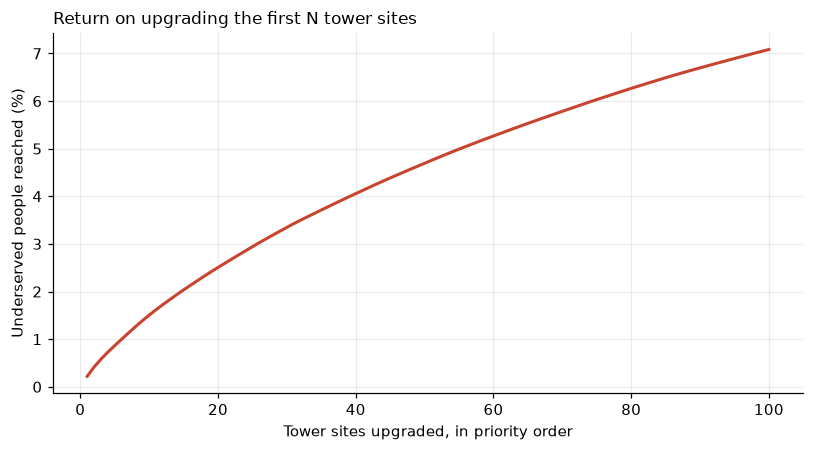

In [47]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(sites["rank"], sites["cumulative_share"] * 100, color=C_ACCENT, linewidth=2)
ax.set_xlabel("Tower sites upgraded, in priority order")
ax.set_ylabel("Underserved people reached (%)")
ax.set_title("Return on upgrading the first N tower sites", loc="left", fontsize=11)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUT / "chart_siting_curve.png", dpi=170, bbox_inches="tight")
plt.show()

## 13. Maps

### 13.1 Zones and states

In [48]:
def draw_classes(ax, gdf, linewidth=0.15):
    """Fill areas by priority class."""
    for cls, color in zip(QUINTILES, QUINTILE_COLORS):
        sub = gdf[gdf["priority_class"] == cls]
        if len(sub):
            sub.plot(ax=ax, facecolor=color, edgecolor="white", linewidth=linewidth, zorder=2)
    ax.set_axis_off()

def class_legend(ax, title):
    handles = [Patch(facecolor=c, edgecolor="#999999", label=l) for l, c in zip(QUINTILES, QUINTILE_COLORS)]
    ax.legend(handles=handles, title=title, loc="lower right", frameon=False)

zone_shapes = states.dissolve(by="zone", as_index=False)[["zone", "geometry"]]      # zones = merged states
zone_map = zone_shapes.merge(zone_tbl[["priority", "priority_class", "priority_rank"]].reset_index(), on="zone")
state_map = states.merge(state_tbl[["priority", "priority_class", "priority_rank"]].reset_index(), on="statecode")

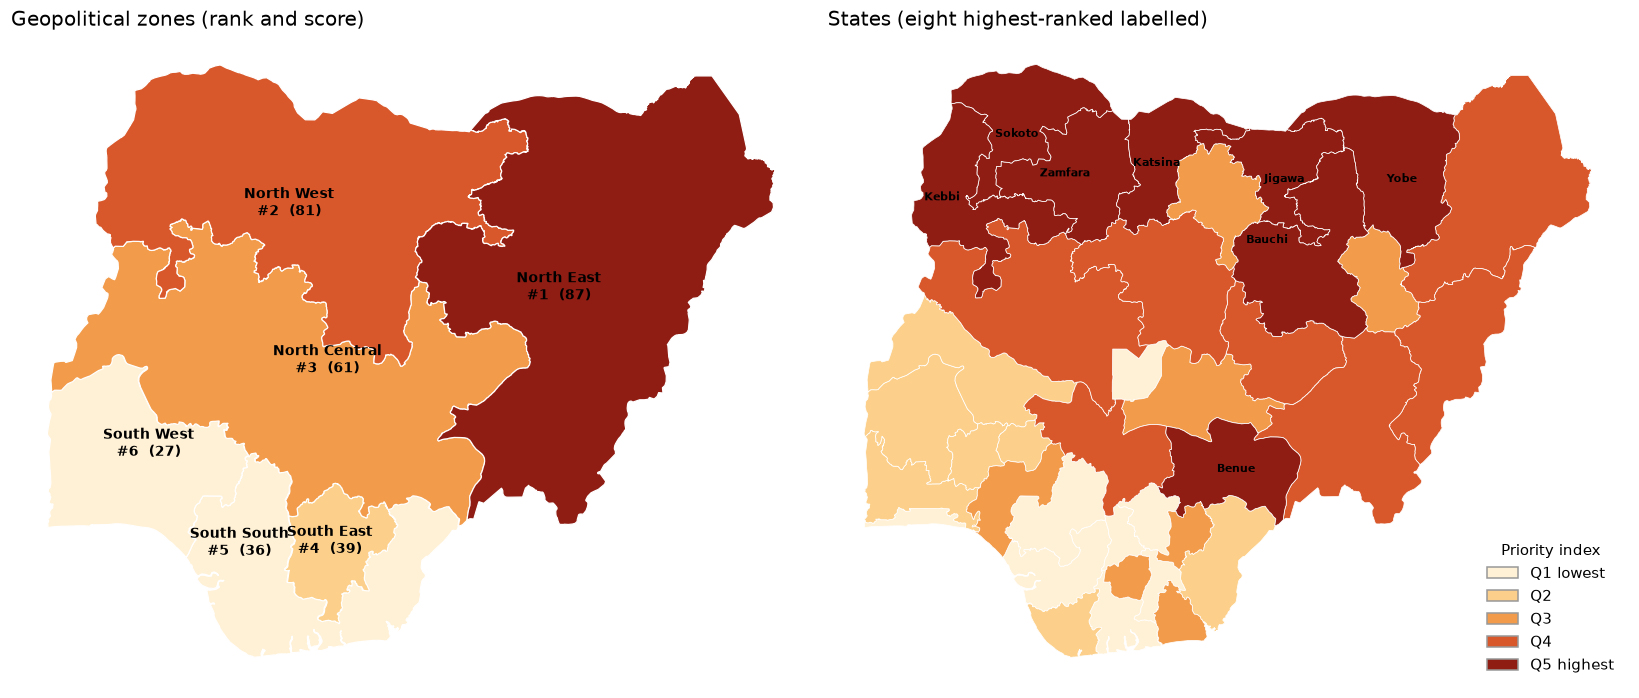

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))

draw_classes(axes[0], zone_map, linewidth=0.8)
for _, row in zone_map.iterrows():
    p = row.geometry.representative_point()
    axes[0].annotate(f"{row['zone']}\n#{row['priority_rank']}  ({row['priority']:.0f})", (p.x, p.y),
                     ha="center", fontsize=9, fontweight="bold", zorder=5)
axes[0].set_title("Geopolitical zones (rank and score)", fontsize=13, loc="left")

draw_classes(axes[1], state_map, linewidth=0.5)
for _, row in state_map[state_map["priority_rank"] <= 8].iterrows():
    p = row.geometry.representative_point()
    axes[1].annotate(f"{row['statename']}", (p.x, p.y), ha="center", fontsize=7.5, fontweight="bold", zorder=5)
axes[1].set_title("States (eight highest-ranked labelled)", fontsize=13, loc="left")
class_legend(axes[1], "Priority index")
plt.tight_layout()
plt.savefig(OUT / "map_zones_states.png", dpi=200, bbox_inches="tight")
plt.show()

### 13.2 LGAs and tower sites

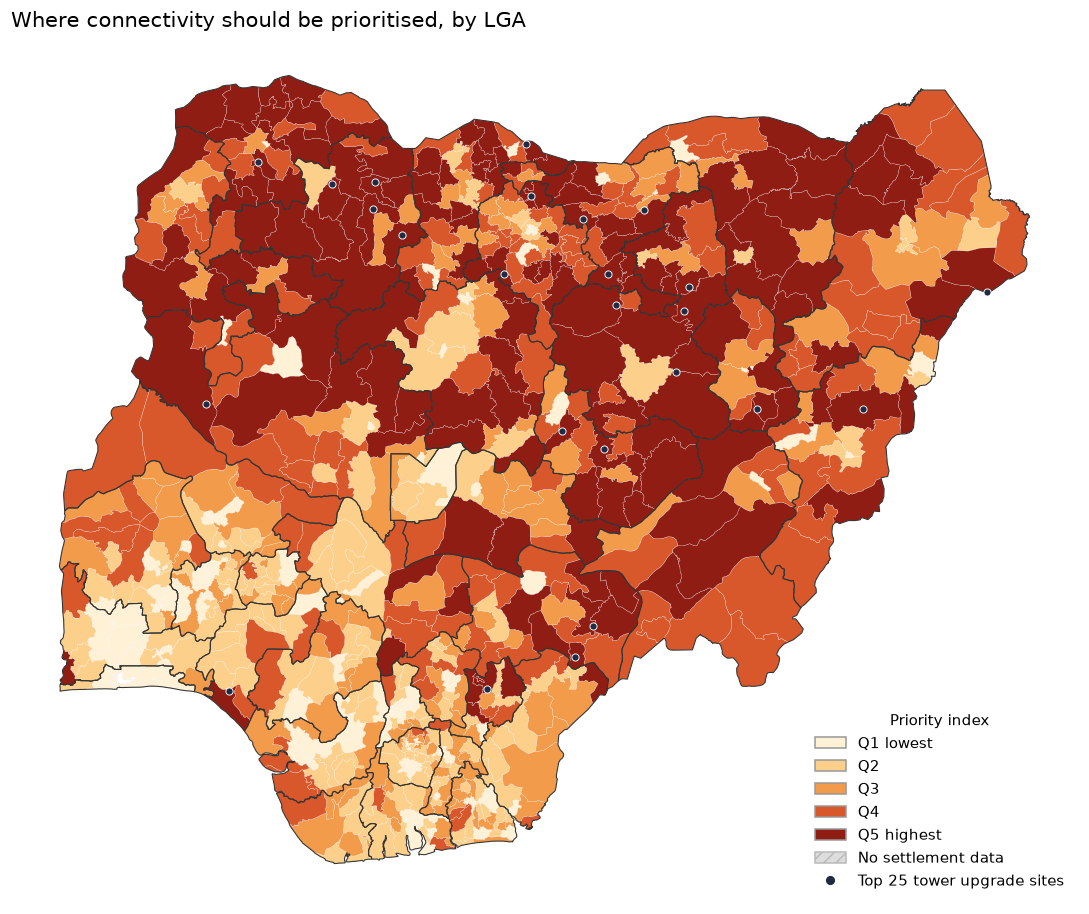

In [50]:
def draw_priority(ax):
    lga.boundary.plot(ax=ax, color="#d0d0cc", linewidth=0.2, zorder=1)
    no_data = lga[lga["buildings"].isna()]
    if len(no_data):
        no_data.plot(ax=ax, facecolor="#dddddd", edgecolor="#bbbbbb", hatch="///", linewidth=0.2, zorder=1)
    draw_classes(ax, scored)
    states.boundary.plot(ax=ax, color="#333333", linewidth=0.7, zorder=4)
    top_sites = sites.head(25)
    ax.scatter(top_sites["lon"], top_sites["lat"], s=22, facecolor=C_DARK, edgecolor="white", linewidth=0.6, zorder=5)

fig, ax = plt.subplots(figsize=(10, 9))
draw_priority(ax)
handles = [Patch(facecolor=c, edgecolor="#999999", label=l) for l, c in zip(QUINTILES, QUINTILE_COLORS)]
handles += [Patch(facecolor="#dddddd", edgecolor="#bbbbbb", hatch="///", label="No settlement data"),
            plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=C_DARK, markeredgecolor="white", markersize=7,
                       label="Top 25 tower upgrade sites")]
ax.legend(handles=handles, title="Priority index", loc="lower right", frameon=False)
ax.set_title("Where connectivity should be prioritised, by LGA", fontsize=14, loc="left")
plt.tight_layout()
plt.savefig(OUT / "priority_map.png", dpi=200, bbox_inches="tight")
plt.show()

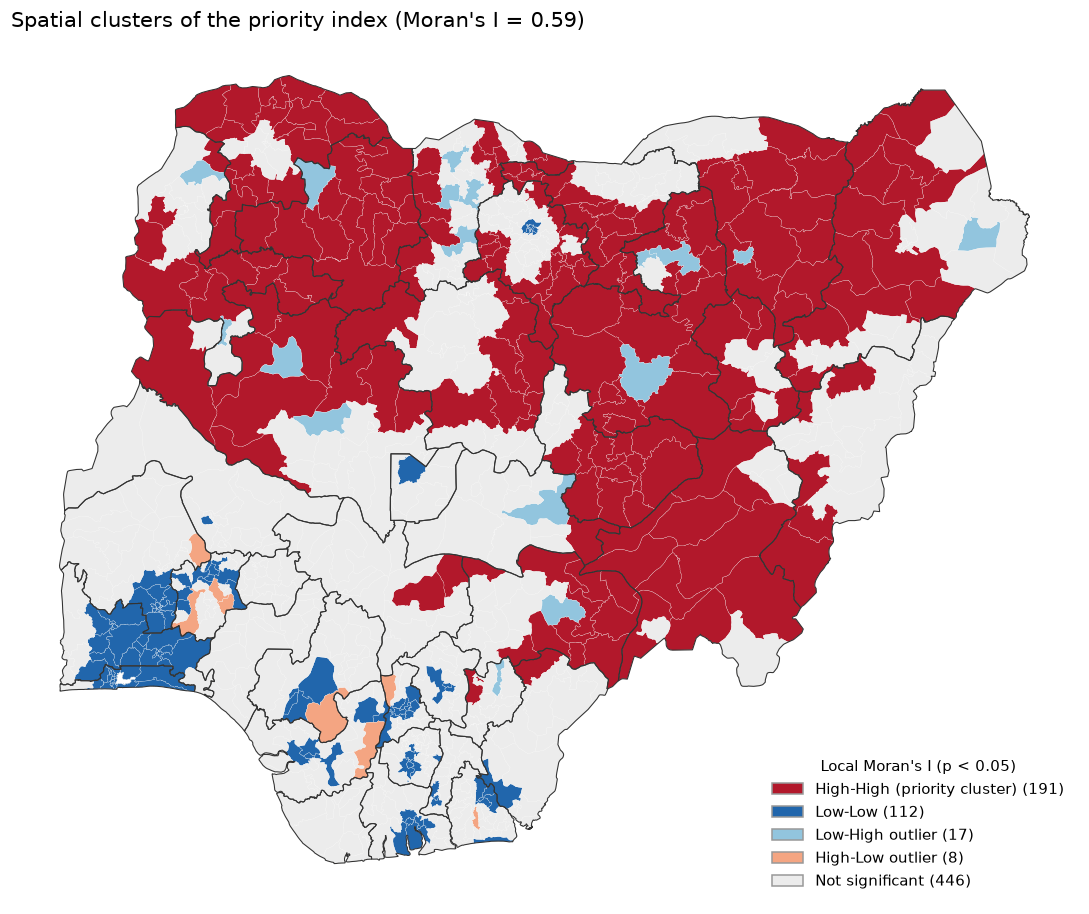

In [51]:
cluster_colors = {"High-High (priority cluster)": "#b2182b", "Low-Low": "#2166ac", "Low-High outlier": "#92c5de",
                  "High-Low outlier": "#f4a582", "Not significant": "#ececec"}
fig, ax = plt.subplots(figsize=(10, 9))
lga.boundary.plot(ax=ax, color="#d0d0cc", linewidth=0.2, zorder=1)
for name, color in cluster_colors.items():
    sub = scored[scored["cluster"] == name]
    if len(sub):
        sub.plot(ax=ax, facecolor=color, edgecolor="white", linewidth=0.15, zorder=2)
states.boundary.plot(ax=ax, color="#333333", linewidth=0.7, zorder=4)
ax.legend(handles=[Patch(facecolor=c, edgecolor="#999999", label=f"{n} ({int((scored['cluster'] == n).sum())})") for n, c in cluster_colors.items()],
          title="Local Moran's I (p < 0.05)", loc="lower right", frameon=False)
ax.set_title(f"Spatial clusters of the priority index (Moran's I = {moran.I:.2f})", fontsize=14, loc="left")
ax.set_axis_off()
plt.tight_layout()
plt.savefig(OUT / "map_clusters.png", dpi=200, bbox_inches="tight")
plt.show()

### 13.3 Interactive map (quick preview)

A standalone preview saved as `outputs/priority_map.html`. The web app uses the files in section 14.

In [52]:
def info_columns(gdf, name_col):
    """Tooltip text for the preview map."""
    out = gdf[[name_col, "priority_class", "priority", "geometry"]].copy()
    out["priority_class"] = out["priority_class"].astype(str)
    out["score"] = out["priority"].round(1).astype(str)
    out["fill"] = out["priority_class"].map(dict(zip(QUINTILES, QUINTILE_COLORS)))
    out["geometry"] = out.geometry.simplify(0.004, preserve_topology=True)
    return out.drop(columns="priority")

lga_preview = info_columns(scored.assign(name=scored["label"]), "name")
state_preview = info_columns(state_map.assign(name=state_map["statename"]), "name")

m = folium.Map(location=[9.1, 8.7], zoom_start=6, tiles="CartoDB positron", control_scale=True)
for data, layer_name, show in [(lga_preview, "LGA priority", True), (state_preview, "State priority", False)]:
    folium.GeoJson(
        data, name=layer_name, show=show,
        style_function=lambda f: {"fillColor": f["properties"]["fill"], "color": "#555555", "weight": 0.5, "fillOpacity": 0.85},
        highlight_function=lambda f: {"weight": 2, "color": "#000000"},
        tooltip=folium.GeoJsonTooltip(fields=["name", "priority_class", "score"], aliases=["Area", "Class", "Score"], sticky=True),
    ).add_to(m)

site_layer = folium.FeatureGroup(name="Top 100 tower upgrade sites")
for _, s in sites.iterrows():
    folium.CircleMarker([s["lat"], s["lon"]], radius=4, color="white", weight=1, fill=True, fill_color=C_DARK, fill_opacity=0.95,
                        tooltip=f"Site {int(s['rank'])}: {s['lga']}, reaches {s['people_reached']:,.0f} people").add_to(site_layer)
site_layer.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m.save(OUT / "priority_map.html")
m

c:\Users\Jinxxx\Desktop\Hussaini\DSN-AI-Hackathon-2026\.venv\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


## 14. Files for the web app

Everything the dashboard and web map need is written to `outputs/web/`, in WGS 84, with missing values as `null`:

* `zones.geojson`, `states.geojson`, `lgas.geojson`: areas with all indicators, score, rank and class.
* `tower_sites.geojson`: the ranked upgrade shortlist.
* `facilities_priority.geojson`: underserved health facilities and schools in the priority LGAs.
* `summary.json`: headline numbers and chart data for the dashboard.
* CSV tables and `DATA_CONTRACT.md`, which lists every field.

In [53]:
AREA_COLS = ["buildings", "population", "underserved_buildings", "underserved_pop", "underserved_share", "unmeasured_share",
             "slow_share", "mean_speed_mbps", "mean_dist_tower_km", "far_share", "mean_rwi", "health", "health_underserved",
             "schools", "schools_underserved", "students", "students_underserved", "institution_share", "service_gap",
             "exposure", "infra_gap", "need", "institution_gap", "priority", "priority_rank", "priority_class"]

def write_geojson(gdf, filename, tolerance):
    """Simplify, round and save an area layer."""
    out = gdf.copy()
    out["geometry"] = out.geometry.simplify(tolerance, preserve_topology=True)
    for col in out.columns:
        if str(out[col].dtype) == "category":
            out[col] = out[col].astype(str)
    out.round(4).to_file(WEB / filename, driver="GeoJSON", COORDINATE_PRECISION=4)

lga_out = scored[["lga_id", "label", "lganame", "statename", "statecode", "zone", "state_rank", "zone_rank",
                  "in_priority_set", "cluster", "top_decile_freq"] + AREA_COLS + ["geometry"]]
state_out = states[["statecode", "statename", "zone", "geometry"]].merge(
    state_tbl.reset_index()[["statecode", "n_lgas"] + AREA_COLS], on="statecode")
zone_out = zone_shapes.merge(zone_tbl.reset_index()[["zone", "n_lgas"] + AREA_COLS], on="zone")

write_geojson(lga_out, "lgas.geojson", 0.004)
write_geojson(state_out, "states.geojson", 0.01)
write_geojson(zone_out, "zones.geojson", 0.02)

In [54]:
# Tower shortlist as points
tower_out = gpd.GeoDataFrame(sites.astype({"radio": str}), geometry=gpd.points_from_xy(sites["lon"], sites["lat"]), crs=CRS_GEO)
tower_out.round(5).to_file(WEB / "tower_sites.geojson", driver="GeoJSON", COORDINATE_PRECISION=5)

# Underserved health facilities and schools inside the priority LGAs
def facility_points(fac, kind, name_col, level_col, owner_col, students=None):
    d = fac[fac["underserved"] & fac["lga_id"].isin(priority_ids)]
    return gpd.GeoDataFrame({
        "kind": kind,
        "name": d[name_col].astype(str).str.slice(0, 60),
        "level": d[level_col].astype(str),
        "owner": d[owner_col].astype(str),
        "status": d["status"],
        "students": d[students] if students else np.nan,
        "lga_id": d["lga_id"].astype(int),
    }, geometry=d.geometry, crs=CRS_GEO)

facility_out = pd.concat([
    facility_points(health, "health", "facility_n", "facility_l", "ownership"),
    facility_points(schools, "school", "name", "education", "management", students="student_ct"),
], ignore_index=True)
facility_out["lga"] = facility_out["lga_id"].map(lgas.set_index("lga_id")["label"])
facility_out.to_file(WEB / "facilities_priority.geojson", driver="GeoJSON", COORDINATE_PRECISION=5)
print(facility_out["kind"].value_counts().to_dict())

{'school': 22386, 'health': 10566}


In [55]:
def records(df, cols):
    """DataFrame rows as plain JSON (NaN becomes null)."""
    return json.loads(df[cols].round(4).to_json(orient="records"))

tot = scored[["buildings", "population", "underserved_buildings", "underserved_pop", "health", "health_underserved",
              "schools", "schools_underserved", "students", "students_underserved"]].sum()
area_cols = ["n_lgas"] + AREA_COLS

summary = {
    "parameters": {"slow_speed_mbps": BROADBAND_MBPS, "tower_radius_km": SITE_RADIUS_KM, "weights": WEIGHTS,
                   "priority_set_share": 1 - PRIORITY_QUANTILE},
    "national": {
        "lgas": int(len(scored)), "buildings": float(tot["buildings"]), "population": float(tot["population"]),
        "underserved_people": float(tot["underserved_pop"]),
        "underserved_share_buildings": float(tot["underserved_buildings"] / tot["buildings"]),
        "health_facilities": int(tot["health"]), "health_underserved": int(tot["health_underserved"]),
        "schools": int(tot["schools"]), "schools_underserved": int(tot["schools_underserved"]),
        "students_underserved": float(tot["students_underserved"]),
        "priority_lgas": int(scored["in_priority_set"].sum()),
        "morans_i": float(moran.I), "wealth_service_spearman": float(rho),
        "sites_shortlisted": int(len(sites)), "share_reached_by_shortlist": float(sites["cumulative_share"].iloc[-1]),
        "share_needing_new_sites": float(beyond_reach),
    },
    "zones": records(zone_tbl.reset_index(), ["zone"] + area_cols),
    "states": records(state_tbl.reset_index(), ["statecode", "state", "zone"] + area_cols),
    "top_lgas": records(scored.sort_values("priority", ascending=False).head(50),
                        ["label", "statename", "zone", "priority", "priority_rank", "population", "underserved_pop",
                         "underserved_share", "mean_dist_tower_km", "mean_rwi", "cluster"]),
    "settlement_types": records(hier.reset_index(), ["ext", "buildings", "served_share", "slow_share", "unmeasured_share", "mean_dist_tower_km"]),
    "siting_curve": records(sites, ["rank", "cumulative_people", "cumulative_share"]),
    "robustness": records(robustness.reset_index(), list(robustness.reset_index().columns)),
}
(WEB / "summary.json").write_text(json.dumps(summary, indent=1), encoding="utf-8")
print("summary.json keys:", list(summary))

summary.json keys: ['parameters', 'national', 'zones', 'states', 'top_lgas', 'settlement_types', 'siting_curve', 'robustness']


In [56]:
# CSV tables and a field list for the front-end developer
scored.sort_values("priority", ascending=False).drop(columns="geometry").round(4).to_csv(WEB / "lgas.csv", index=False)
state_tbl.reset_index().round(4).to_csv(WEB / "states.csv", index=False)
zone_tbl.reset_index().round(4).to_csv(WEB / "zones.csv", index=False)
sites.round(5).to_csv(WEB / "tower_sites.csv", index=False)

contract = ["# Web data contract", "", "All coordinates are WGS 84 (EPSG:4326). Missing values are null.", ""]
for fname, cols in [("lgas.geojson", lga_out.columns), ("states.geojson", state_out.columns), ("zones.geojson", zone_out.columns),
                    ("tower_sites.geojson", tower_out.columns), ("facilities_priority.geojson", facility_out.columns)]:
    contract += [f"## {fname}", "", ", ".join(f"`{c}`" for c in cols if c != "geometry"), ""]
contract += ["## summary.json", "", "Keys: " + ", ".join(f"`{k}`" for k in summary), ""]
(WEB / "DATA_CONTRACT.md").write_text("\n".join(contract), encoding="utf-8")

for f in sorted(WEB.glob("*")):
    print(f"{f.name:<30}{f.stat().st_size / 1e6:>8.2f} MB")

DATA_CONTRACT.md                  0.00 MB
facilities_priority.geojson       9.61 MB
lgas.csv                          0.28 MB
lgas.geojson                      1.52 MB
states.csv                        0.01 MB
states.geojson                    0.12 MB
summary.json                      0.07 MB
tower_sites.csv                   0.01 MB
tower_sites.geojson               0.04 MB
zones.csv                         0.00 MB
zones.geojson                     0.03 MB


C:\Users\Jinxxx\AppData\Local\Temp\ipykernel_10188\170558878.py:2: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  scored.sort_values("priority", ascending=False).drop(columns="geometry").round(4).to_csv(WEB / "lgas.csv", index=False)


## 15. Findings

All numbers are computed from the results above.

In [57]:
nat = summary["national"]
unmeasured_share = (hier["buildings"] * hier["unmeasured_share"]).sum() / hier["buildings"].sum()
slow_share = (hier["buildings"] * hier["slow_share"]).sum() / hier["buildings"].sum()
ps = scored[scored["in_priority_set"]]

print("1. Many people live where no speed was measured")
print(f"   {unmeasured_share:.1%} of buildings are outside any Ookla tile and {slow_share:.1%} are in tiles under "
      f"{BROADBAND_MBPS:.0f} Mbps. About {nat['underserved_people']:,.0f} of {nat['population']:,.0f} people live in underserved buildings.\n")

print("2. Zones")
for zone, r in zone_tbl.iterrows():
    print(f"   #{r['priority_rank']} {zone:<14} score {r['priority']:.0f}, {r['underserved_share']:.1%} of buildings underserved, {r['underserved_pop']:,.0f} people")

print("\n3. States (top 5)")
for _, r in state_tbl.head(5).iterrows():
    print(f"   #{r['priority_rank']} {r['state']} ({r['zone']}): score {r['priority']:.0f}, {r['underserved_pop']:,.0f} underserved people")

print("\n4. Settlement types")
for name, r in hier.iterrows():
    print(f"   {name:<24} unmeasured {r['unmeasured_share']:.1%}, slow {r['slow_share']:.1%}, served {r['served_share']:.1%}")

print("\n5. Wealth and clustering")
print(f"   Spearman correlation of wealth with underserved share: {rho:.2f}. Moran's I of the priority index: {moran.I:.2f}; "
      f"{int((scored['cluster'] == 'High-High (priority cluster)').sum())} LGAs sit in significant priority clusters.")

print("\n6. Schools and health facilities")
print(f"   Health facilities underserved: {nat['health_underserved']:,} of {nat['health_facilities']:,}. "
      f"Schools underserved: {nat['schools_underserved']:,} of {nat['schools']:,}. "
      f"Students in those schools (where counts exist): {nat['students_underserved']:,.0f}.")

print("\n7. Action list")
print(f"   The {len(ps)} priority LGAs hold {ps['underserved_pop'].sum() / scored['underserved_pop'].sum():.1%} of underserved people. "
      f"The first {len(sites)} upgraded towers reach {nat['share_reached_by_shortlist']:.1%} of those in priority LGAs; "
      f"{nat['share_needing_new_sites']:.1%} are beyond reach of every candidate tower.")

1. Many people live where no speed was measured
   90.5% of buildings are outside any Ookla tile and 3.1% are in tiles under 10 Mbps. About 195,147,026 of 211,661,940 people live in underserved buildings.

2. Zones
   #1 North East     score 87, 98.6% of buildings underserved, 28,486,832 people
   #2 North West     score 81, 96.9% of buildings underserved, 50,136,719 people
   #3 North Central  score 61, 94.1% of buildings underserved, 30,262,434 people
   #4 South East     score 39, 94.5% of buildings underserved, 22,416,565 people
   #5 South South    score 36, 89.3% of buildings underserved, 27,926,519 people
   #6 South West     score 27, 83.1% of buildings underserved, 35,917,958 people

3. States (top 5)
   #1 Zamfara (North West): score 87, 4,746,855 underserved people
   #2 Bauchi (North East): score 86, 6,982,231 underserved people
   #3 Jigawa (North West): score 81, 5,828,897 underserved people
   #4 Benue (North Central): score 80, 5,872,848 underserved people
   #5 Katsina

## 16. Recommendations

In [58]:
top_zone = zone_tbl.index[0]
top_states_txt = ", ".join(state_tbl.head(5)["state"])
top_lgas_txt = ", ".join(scored.sort_values("priority", ascending=False).head(5)["label"])

print(f"1. Start with the {top_zone} zone, then these states: {top_states_txt}.")
print(f"   Within them, the first LGAs to act on are: {top_lgas_txt}. Full lists are in outputs/web/.\n")
print("2. Upgrade existing towers before building new ones.")
print(f"   The shortlist in tower_sites.csv is ordered by people newly reached; the first 25 reach "
      f"{sites['cumulative_share'].iloc[min(24, len(sites) - 1)]:.1%} of underserved people in the priority LGAs.\n")
print("3. Plan new sites only where no tower is within reach.")
print(f"   {nat['share_needing_new_sites']:.1%} of underserved people in priority LGAs are beyond {SITE_RADIUS_KM:.0f} km of every candidate tower.\n")
print("4. Connect schools and clinics early.")
print(f"   {nat['schools_underserved']:,} schools and {nat['health_underserved']:,} health facilities are in unmeasured or slow locations; "
      "those in priority LGAs are mapped in facilities_priority.geojson.\n")
print("5. Close the measurement gap.")
print(f"   {unmeasured_share:.1%} of buildings have no speed test. Field tests or operator coverage data in the priority LGAs would show which are truly unserved.")

1. Start with the North East zone, then these states: Zamfara, Bauchi, Jigawa, Benue, Katsina.
   Within them, the first LGAs to act on are: Maru (Zamfara), Alkaleri (Bauchi), Katsina-Ala (Benue), Bukkuyum (Zamfara), Ningi (Bauchi). Full lists are in outputs/web/.

2. Upgrade existing towers before building new ones.
   The shortlist in tower_sites.csv is ordered by people newly reached; the first 25 reach 2.9% of underserved people in the priority LGAs.

3. Plan new sites only where no tower is within reach.
   85.6% of underserved people in priority LGAs are beyond 3 km of every candidate tower.

4. Connect schools and clinics early.
   98,883 schools and 46,641 health facilities are in unmeasured or slow locations; those in priority LGAs are mapped in facilities_priority.geojson.

5. Close the measurement gap.
   90.5% of buildings have no speed test. Field tests or operator coverage data in the priority LGAs would show which are truly unserved.


## 17. Limitations, sources and next steps

**Limitations**
* Ookla tiles exist only where tests were run, and many rest on one or two tests. Unmeasured means weak or absent usage, not proof of no signal.
* Underserved people are estimated by sharing each LGA's population in proportion to its underserved buildings.
* OpenCelliD is crowd-sourced; 3G and 4G towers are probably under-recorded, so tower distance measures proximity to infrastructure, not coverage.
* The Relative Wealth Index is modelled and relative. School student counts are missing for some schools.
* The layers come from different years. The 3 km tower reach is an assumption, and the siting step ignores terrain, power and backhaul.
* Index weights are a judgement; section 9.1 shows how much the ranking depends on them.

**Sources:** Speedtest by Ookla open data; GRID3 Nigeria (settlements, boundaries, health facilities, schools); WorldPop (population); OpenCelliD (CC BY-SA 4.0); Meta Data for Good (Relative Wealth Index). Each is used under its provider's terms.

**Next steps:** validate the priority LGAs against operator coverage or field tests; add terrain and electricity to the siting step; refine people estimates with block-level population.